In [ ]:
# =============================================================================
# FINAL BUDGET NOTEBOOK V4
# Machine Learning Class Project - Budget Subgroup
#
# This notebook is the final polished budget-subgroup notebook.
#
# Why this notebook is structured this way:
# - Earlier versions showed that exact billing amount regression performed poorly.
# - Because of that, this final notebook uses billing category classification
#   (Low / Medium / High) instead of raw billing regression.
# - Billing category classification is the primary focus because it produced the
#   strongest and most presentable results in earlier iterations.
# - Insurance provider prediction is kept as a secondary exploratory question.
# - High-cost prediction is included only briefly because it remained difficult
#   on the synthetic dataset and is best discussed as a limitation rather than
#   as the main success story.
#
# Final notebook structure:
#   A. Data cleaning and feature engineering
#   B. Target creation
#   C. Shared train/test split
#   D. Final preprocessing strategy
#   E. Primary result: billing category classification
#   F. Secondary result: insurance provider prediction
#   G. Brief high-cost prediction section
#   H. Final summary and interpretation
#
# File expected in Colab working directory:
#   healthcare_dataset_with_system.csv
# =============================================================================

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

# -----------------------------------------------------------------------------
# Helper print functions for cleaner notebook output
# -----------------------------------------------------------------------------
def print_header(title):
    print("\n" + "=" * 90)
    print(title)
    print("=" * 90)

def print_subheader(title):
    print("\n" + "-" * 70)
    print(title)
    print("-" * 70)

# -----------------------------------------------------------------------------
# Helper function: robust OneHotEncoder for Colab / sklearn version differences
# -----------------------------------------------------------------------------
def make_ohe():
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

# -----------------------------------------------------------------------------
# Helper function: fit frequency maps on training only
# This avoids data leakage for high-cardinality features.
# -----------------------------------------------------------------------------
def fit_frequency_maps(train_df, cols):
    freq_maps = {}
    for c in cols:
        freq_maps[c] = train_df[c].fillna("Missing").value_counts(normalize=True).to_dict()
    return freq_maps

# -----------------------------------------------------------------------------
# Helper function: apply training-derived frequency maps to any dataframe
# -----------------------------------------------------------------------------
def apply_frequency_encoding(df_in, cols, freq_maps):
    df_out = df_in.copy()
    for c in cols:
        df_out[f"{c}_freq"] = (
            df_out[c]
            .fillna("Missing")
            .map(freq_maps[c])
            .fillna(0.0)
            .astype(float)
        )
    df_out = df_out.drop(columns=cols, errors="ignore")
    return df_out

# -----------------------------------------------------------------------------
# Helper function: identify numeric, low-cardinality categorical, and
# high-cardinality variables
# -----------------------------------------------------------------------------
def identify_feature_groups(X):
    high_card_cols = [c for c in ["doctor", "hospital"] if c in X.columns]
    numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
    low_card_categorical = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
    low_card_categorical = [c for c in low_card_categorical if c not in high_card_cols]
    return numeric_features, low_card_categorical, high_card_cols

# -----------------------------------------------------------------------------
# Helper function: build sklearn preprocessor
# -----------------------------------------------------------------------------
def build_preprocessor(numeric_features, low_card_categorical):
    preprocessor = ColumnTransformer(
        transformers=[
            ("num", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), numeric_features),
            ("cat", Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", make_ohe())
            ]), low_card_categorical)
        ],
        remainder="drop"
    )
    return preprocessor

# -----------------------------------------------------------------------------
# Helper function: prepare a target-specific dataset
# -----------------------------------------------------------------------------
def prepare_task_data(data, target_col, train_idx, test_idx):
    # Drop raw datetime columns after engineered date features are created
    raw_date_cols = [c for c in ["date_of_admission", "discharge_date"] if c in data.columns]

    # Name is dropped because it is an identifier-like field and not useful
    drop_cols = ["name"] + raw_date_cols

    # Prevent target leakage by dropping other target variables
    possible_targets = ["billing_amount", "billing_category", "high_cost_flag", "insurance_provider"]
    leakage_targets = [c for c in possible_targets if c in data.columns and c != target_col]

    X = data.drop(columns=drop_cols + leakage_targets + [target_col], errors="ignore").copy()
    y = data[target_col].copy()

    X_train = X.iloc[train_idx].copy()
    X_test = X.iloc[test_idx].copy()
    y_train = y.iloc[train_idx].copy()
    y_test = y.iloc[test_idx].copy()

    numeric_features, low_card_categorical, high_card_cols = identify_feature_groups(X_train)

    # Frequency encoding learned from training only
    freq_maps = fit_frequency_maps(X_train, high_card_cols)
    X_train_enc = apply_frequency_encoding(X_train, high_card_cols, freq_maps)
    X_test_enc = apply_frequency_encoding(X_test, high_card_cols, freq_maps)

    freq_cols = [f"{c}_freq" for c in high_card_cols]
    numeric_features_final = [c for c in numeric_features if c in X_train_enc.columns] + freq_cols
    low_card_final = [c for c in low_card_categorical if c in X_train_enc.columns]

    preprocessor = build_preprocessor(numeric_features_final, low_card_final)

    print_subheader(f"Prepared data for target: {target_col}")
    print("X_train shape:", X_train_enc.shape)
    print("X_test shape :", X_test_enc.shape)
    print("\nTarget distribution in training data:")
    print(y_train.value_counts(dropna=False))
    print("\nNumeric features:")
    print(numeric_features_final)
    print("\nLow-cardinality categorical features:")
    print(low_card_final)
    print("\nHigh-cardinality frequency-encoded features:")
    print(freq_cols)

    return X_train_enc, X_test_enc, y_train, y_test, preprocessor

# -----------------------------------------------------------------------------
# Helper functions for evaluation
# -----------------------------------------------------------------------------
def evaluate_multiclass(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro_F1": f1_score(y_true, y_pred, average="macro"),
        "Weighted_F1": f1_score(y_true, y_pred, average="weighted"),
        "Confusion_Matrix": confusion_matrix(y_true, y_pred),
        "Classification_Report": classification_report(y_true, y_pred, zero_division=0)
    }

def evaluate_binary(y_true, y_pred, y_prob=None):
    results = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_Class1": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall_Class1": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1_Class1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Confusion_Matrix": confusion_matrix(y_true, y_pred),
        "Classification_Report": classification_report(y_true, y_pred, zero_division=0)
    }
    if y_prob is not None:
        results["ROC_AUC"] = roc_auc_score(y_true, y_prob)
    else:
        results["ROC_AUC"] = np.nan
    return results

# =============================================================================
# PART B - DATA CLEANING AND PREPARATION
# =============================================================================
print_header("PART B - DATA CLEANING AND PREPARATION")

df = pd.read_csv("healthcare_dataset_with_system.csv")

print("\nOriginal shape:")
print(df.shape)

print("\nOriginal columns:")
print(df.columns.tolist())

# Standardize column names
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_", regex=False)
    .str.replace("/", "_", regex=False)
)

print("\nCleaned column names:")
print(df.columns.tolist())

# Clean text columns
text_cols = [
    "name", "gender", "blood_type", "medical_condition", "doctor", "hospital",
    "insurance_provider", "admission_type", "medication", "test_results", "hospital_system"
]
existing_text_cols = [c for c in text_cols if c in df.columns]
for c in existing_text_cols:
    df[c] = df[c].astype(str).str.strip().str.title()

print("\nText columns cleaned:")
print(existing_text_cols)

# Convert date columns
for c in [c for c in ["date_of_admission", "discharge_date"] if c in df.columns]:
    df[c] = pd.to_datetime(df[c], errors="coerce")

print("\nDate column dtypes:")
print(df[[c for c in ["date_of_admission", "discharge_date"] if c in df.columns]].dtypes)

# Convert numeric columns
for c in [c for c in ["age", "billing_amount", "room_number"] if c in df.columns]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

print("\nNumeric column dtypes:")
print(df[[c for c in ["age", "billing_amount", "room_number"] if c in df.columns]].dtypes)

# Remove duplicates
rows_before = len(df)
df = df.drop_duplicates().copy()
rows_after = len(df)

print("\nDuplicate removal:")
print("Rows before:", rows_before)
print("Rows after :", rows_after)
print("Duplicates removed:", rows_before - rows_after)

# -----------------------------------------------------------------------------
# Feature engineering
# -----------------------------------------------------------------------------
# Baseline engineered features from earlier versions
df["length_of_stay"] = (df["discharge_date"] - df["date_of_admission"]).dt.days
df.loc[df["length_of_stay"] < 0, "length_of_stay"] = np.nan

df["admission_year"] = df["date_of_admission"].dt.year
df["admission_month"] = df["date_of_admission"].dt.month
df["admission_dayofweek"] = df["date_of_admission"].dt.day_name()

df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 18, 35, 50, 65, 120],
    labels=["0-18", "19-35", "36-50", "51-65", "66+"],
    include_lowest=True
)

df["los_band"] = pd.cut(
    df["length_of_stay"],
    bins=[-np.inf, 2, 5, 10, np.inf],
    labels=["Short", "Medium", "Long", "Very_Long"]
)

df["age_band_finer"] = pd.cut(
    df["age"],
    bins=[0, 25, 40, 55, 70, 120],
    labels=["0-25", "26-40", "41-55", "56-70", "71+"],
    include_lowest=True
)

admission_lower = df["admission_type"].astype(str).str.lower()
df["is_emergency"] = admission_lower.str.contains("emergency", na=False).astype(int)
df["is_urgent"] = admission_lower.str.contains("urgent", na=False).astype(int)

# Group conditions and medications
condition_counts = df["medical_condition"].value_counts()
common_conditions = condition_counts[condition_counts >= 1000].index.tolist()
df["condition_group"] = np.where(df["medical_condition"].isin(common_conditions), df["medical_condition"], "Other")

medication_counts = df["medication"].value_counts()
common_meds = medication_counts[medication_counts >= 1000].index.tolist()
df["medication_group"] = np.where(df["medication"].isin(common_meds), df["medication"], "Other")

# Final useful budget-oriented engineered flags
df["weekend_admission"] = df["admission_dayofweek"].isin(["Saturday", "Sunday"]).astype(int)
df["long_stay_flag"] = (df["length_of_stay"] >= 7).astype(int)
df["senior_flag"] = (df["age"] >= 65).astype(int)

print("\nFinal shape after engineering:")
print(df.shape)

print("\nMissing values by column:")
print(df.isna().sum())

print("\nKey distributions:")
for c in ["admission_type", "hospital_system", "medical_condition", "los_band", "age_band_finer"]:
    print(f"\nDistribution for {c}:")
    print(df[c].value_counts(dropna=False))

print("\nSample rows after preparation:")
print(df.head())

# =============================================================================
# PART C - FINAL TARGETS
# =============================================================================
print_header("PART C - FINAL TARGETS")

# Primary budget target:
# Billing category is preferred over raw billing regression because earlier
# attempts at exact billing regression performed poorly.
df["billing_category"] = pd.qcut(
    df["billing_amount"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# High-cost target kept briefly for limitation discussion
high_cost_threshold = df["billing_amount"].quantile(0.85)
df["high_cost_flag"] = (df["billing_amount"] >= high_cost_threshold).astype(int)

print("\nHigh-cost threshold (top 15%):", round(high_cost_threshold, 4))

print("\nBilling category distribution:")
print(df["billing_category"].value_counts(dropna=False))

print("\nHigh-cost flag distribution:")
print(df["high_cost_flag"].value_counts(dropna=False))

print("\nInsurance provider distribution:")
print(df["insurance_provider"].value_counts(dropna=False))

# =============================================================================
# PART D - SHARED SPLIT
# =============================================================================
print_header("PART D - SHARED 80/20 TRAIN-TEST SPLIT")

all_idx = np.arange(len(df))
train_idx, test_idx = train_test_split(
    all_idx,
    test_size=0.2,
    random_state=42
)

print("\nTrain size:", len(train_idx))
print("Test size :", len(test_idx))

# =============================================================================
# PART E - FINAL PREPROCESSING
# =============================================================================
print_header("PART E - FINAL PREPROCESSING STRATEGY")

print("\nThis notebook uses the following final preprocessing strategy:")
print("- Drop 'name' because it is identifier-like and not useful for modeling.")
print("- Do not use raw datetime columns directly after engineering date-based features.")
print("- One-hot encode low-cardinality categorical variables.")
print("- Frequency encode high-cardinality variables ('doctor' and 'hospital') using training data only.")
print("- Median impute and standardize numeric variables.")
print("- Keep 'hospital_system' because it was intentionally added to the dataset and may carry system-level signal.")

# =============================================================================
# PART F - PRIMARY QUESTION: BILLING CATEGORY CLASSIFICATION
# =============================================================================
print_header("PART F - PRIMARY QUESTION: BILLING CATEGORY CLASSIFICATION")

print("\nNote:")
print("Billing category classification is the primary budget result in this notebook.")
print("It is used instead of raw billing amount regression because raw regression performed poorly in earlier versions.")

X_train_bill, X_test_bill, y_train_bill, y_test_bill, pre_bill = prepare_task_data(
    df, "billing_category", train_idx, test_idx
)

billing_models = {
    "Multinomial Logistic Regression": LogisticRegression(max_iter=4000, multi_class="multinomial"),
    "Random Forest": RandomForestClassifier(n_estimators=250, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=250, random_state=42, n_jobs=-1)
}

billing_results = {}
billing_pipes = {}

for model_name, model in billing_models.items():
    print_subheader(f"Training billing category model: {model_name}")

    pipe = Pipeline(steps=[
        ("preprocessor", pre_bill),
        ("model", model)
    ])

    pipe.fit(X_train_bill, y_train_bill)
    y_pred = pipe.predict(X_test_bill)

    metrics = evaluate_multiclass(y_test_bill, y_pred)
    billing_results[model_name] = {
        "Accuracy": metrics["Accuracy"],
        "Macro_F1": metrics["Macro_F1"],
        "Weighted_F1": metrics["Weighted_F1"]
    }
    billing_pipes[model_name] = pipe

    print("Accuracy    :", round(metrics["Accuracy"], 4))
    print("Macro F1    :", round(metrics["Macro_F1"], 4))
    print("Weighted F1 :", round(metrics["Weighted_F1"], 4))

billing_results_df = pd.DataFrame(billing_results).T.sort_values(by="Macro_F1", ascending=False)

print("\nBilling category comparison table:")
print(billing_results_df)

best_billing_model_name = billing_results_df.index[0]
best_billing_pipe = billing_pipes[best_billing_model_name]
best_billing_pred = best_billing_pipe.predict(X_test_bill)
best_billing_metrics = evaluate_multiclass(y_test_bill, best_billing_pred)

print("\nBest billing category model:", best_billing_model_name)
print("Best billing Macro F1:", round(best_billing_metrics["Macro_F1"], 4))

print("\nConfusion matrix for best billing model:")
print(best_billing_metrics["Confusion_Matrix"])

print("\nClassification report for best billing model:")
print(best_billing_metrics["Classification_Report"])

# =============================================================================
# PART G - SECONDARY QUESTION: INSURANCE PROVIDER PREDICTION
# =============================================================================
print_header("PART G - SECONDARY QUESTION: INSURANCE PROVIDER PREDICTION")

print("\nNote:")
print("Insurance provider prediction is included as a secondary exploratory question.")
print("It is weaker than billing category classification, but it still shows some signal and is worth reporting briefly.")

X_train_ins, X_test_ins, y_train_ins, y_test_ins, pre_ins = prepare_task_data(
    df, "insurance_provider", train_idx, test_idx
)

insurance_models = {
    "Multinomial Logistic Regression": LogisticRegression(max_iter=4000, multi_class="multinomial"),
    "Random Forest": RandomForestClassifier(n_estimators=250, random_state=42, n_jobs=-1),
    "Extra Trees": ExtraTreesClassifier(n_estimators=250, random_state=42, n_jobs=-1)
}

insurance_results = {}
insurance_pipes = {}

for model_name, model in insurance_models.items():
    print_subheader(f"Training insurance provider model: {model_name}")

    pipe = Pipeline(steps=[
        ("preprocessor", pre_ins),
        ("model", model)
    ])

    pipe.fit(X_train_ins, y_train_ins)
    y_pred = pipe.predict(X_test_ins)

    metrics = evaluate_multiclass(y_test_ins, y_pred)
    insurance_results[model_name] = {
        "Accuracy": metrics["Accuracy"],
        "Macro_F1": metrics["Macro_F1"],
        "Weighted_F1": metrics["Weighted_F1"]
    }
    insurance_pipes[model_name] = pipe

    print("Accuracy    :", round(metrics["Accuracy"], 4))
    print("Macro F1    :", round(metrics["Macro_F1"], 4))
    print("Weighted F1 :", round(metrics["Weighted_F1"], 4))

insurance_results_df = pd.DataFrame(insurance_results).T.sort_values(by="Macro_F1", ascending=False)

print("\nInsurance provider comparison table:")
print(insurance_results_df)

best_insurance_model_name = insurance_results_df.index[0]
best_insurance_pipe = insurance_pipes[best_insurance_model_name]
best_insurance_pred = best_insurance_pipe.predict(X_test_ins)
best_insurance_metrics = evaluate_multiclass(y_test_ins, best_insurance_pred)

print("\nBest insurance provider model:", best_insurance_model_name)
print("Best insurance Macro F1:", round(best_insurance_metrics["Macro_F1"], 4))

print("\nConfusion matrix for best insurance model:")
print(best_insurance_metrics["Confusion_Matrix"])

print("\nClassification report for best insurance model:")
print(best_insurance_metrics["Classification_Report"])

# =============================================================================
# PART H - BRIEF HIGH-COST SECTION
# =============================================================================
print_header("PART H - BRIEF HIGH-COST PREDICTION SECTION")

print("\nNote:")
print("High-cost prediction remained difficult in earlier versions.")
print("For that reason, it is included here only briefly as a supporting limitation section.")
print("It is NOT the main result of this notebook.")

X_train_high, X_test_high, y_train_high, y_test_high, pre_high = prepare_task_data(
    df, "high_cost_flag", train_idx, test_idx
)

high_cost_models = {
    "Logistic Regression Balanced": LogisticRegression(max_iter=4000, class_weight="balanced"),
    "Random Forest Balanced": RandomForestClassifier(
        n_estimators=250,
        random_state=42,
        n_jobs=-1,
        class_weight="balanced"
    )
}

high_cost_results = {}
high_cost_pipes = {}

for model_name, model in high_cost_models.items():
    print_subheader(f"Training high-cost model: {model_name}")

    pipe = Pipeline(steps=[
        ("preprocessor", pre_high),
        ("model", model)
    ])

    pipe.fit(X_train_high, y_train_high)

    # Use default threshold here for final polished notebook simplicity.
    # Earlier versions tried more threshold tuning, but this final notebook
    # keeps the high-cost section concise because it is not the main focus.
    y_pred = pipe.predict(X_test_high)

    if hasattr(pipe, "predict_proba"):
        y_prob = pipe.predict_proba(X_test_high)[:, 1]
    else:
        y_prob = None

    metrics = evaluate_binary(y_test_high, y_pred, y_prob)

    high_cost_results[model_name] = {
        "Accuracy": metrics["Accuracy"],
        "Precision_Class1": metrics["Precision_Class1"],
        "Recall_Class1": metrics["Recall_Class1"],
        "F1_Class1": metrics["F1_Class1"],
        "ROC_AUC": metrics["ROC_AUC"]
    }
    high_cost_pipes[model_name] = pipe

    print("Accuracy           :", round(metrics["Accuracy"], 4))
    print("Precision (class 1):", round(metrics["Precision_Class1"], 4))
    print("Recall (class 1)   :", round(metrics["Recall_Class1"], 4))
    print("F1 (class 1)       :", round(metrics["F1_Class1"], 4))
    print("ROC AUC            :", round(metrics["ROC_AUC"], 4) if not np.isnan(metrics["ROC_AUC"]) else "N/A")

high_cost_results_df = pd.DataFrame(high_cost_results).T.sort_values(by="F1_Class1", ascending=False)

print("\nHigh-cost comparison table:")
print(high_cost_results_df)

best_high_cost_model_name = high_cost_results_df.index[0]
best_high_cost_f1 = high_cost_results_df.iloc[0]["F1_Class1"]

# =============================================================================
# PART I - FINAL SUMMARY AND INTERPRETATION
# =============================================================================
print_header("PART I - FINAL SUMMARY AND INTERPRETATION")

best_billing_macro_f1 = billing_results_df.iloc[0]["Macro_F1"]
best_insurance_macro_f1 = insurance_results_df.iloc[0]["Macro_F1"]

print("\nBest model for billing category:")
print(best_billing_model_name)
print("Best billing Macro F1:", round(best_billing_macro_f1, 4))

print("\nBest model for insurance provider:")
print(best_insurance_model_name)
print("Best insurance Macro F1:", round(best_insurance_macro_f1, 4))

print("\nBest model for high-cost:")
print(best_high_cost_model_name)
print("Best high-cost F1 for class 1:", round(best_high_cost_f1, 4))

print("\nFinal interpretation:")
print("- Billing category is the strongest budget result and should be highlighted in the final presentation.")
print("- Insurance provider prediction shows some signal but is weaker and should be treated as a secondary exploratory result.")
print("- High-cost prediction remained difficult on the synthetic dataset and is better discussed as a limitation rather than as a primary success.")

print("\nFinal comparison tables:")

print("\nBilling category results:")
print(billing_results_df)

print("\nInsurance provider results:")
print(insurance_results_df)

print("\nHigh-cost results:")
print(high_cost_results_df)

print("\nThis notebook is the FINAL budget subgroup notebook.")
print("It is structured to emphasize the strongest budget result (billing category),")
print("include a secondary exploratory result (insurance provider),")
print("and briefly document a weaker limitation result (high-cost prediction).")

# Optional save of working dataset for reproducibility
df.to_csv("budget_v4_working_dataset.csv", index=False)
print("\nSaved working dataset as: budget_v4_working_dataset.csv")


PART B - DATA CLEANING AND PREPARATION

Original shape:
(55500, 16)

Original columns:
['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition', 'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider', 'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date', 'Medication', 'Test Results', 'Hospital System']

Cleaned column names:
['name', 'age', 'gender', 'blood_type', 'medical_condition', 'date_of_admission', 'doctor', 'hospital', 'insurance_provider', 'billing_amount', 'room_number', 'admission_type', 'discharge_date', 'medication', 'test_results', 'hospital_system']

Text columns cleaned:
['name', 'gender', 'blood_type', 'medical_condition', 'doctor', 'hospital', 'insurance_provider', 'admission_type', 'medication', 'test_results', 'hospital_system']

Date column dtypes:
date_of_admission    datetime64[ns]
discharge_date       datetime64[ns]
dtype: object

Numeric column dtypes:
age                 int64
billing_amount    float64
room_number         int64
dtyp


==========================================================================================
PART B - DATA CLEANING AND PREPARATION
==========================================================================================

Original shape:
(55500, 16)

Original columns:
['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition', 'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider', 'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date', 'Medication', 'Test Results', 'Hospital System']

Cleaned column names:
['name', 'age', 'gender', 'blood_type', 'medical_condition', 'date_of_admission', 'doctor', 'hospital', 'insurance_provider', 'billing_amount', 'room_number', 'admission_type', 'discharge_date', 'medication', 'test_results', 'hospital_system']

Text columns cleaned:
['name', 'gender', 'blood_type', 'medical_condition', 'doctor', 'hospital', 'insurance_provider', 'admission_type', 'medication', 'test_results', 'hospital_system']

Date column dtypes:
date_of_admission    datetime64[ns]
discharge_date       datetime64[ns]
dtype: object

Numeric column dtypes:
age                 int64
billing_amount    float64
room_number         int64
dtype: object

Duplicate removal:
Rows before: 55500
Rows after : 54966
Duplicates removed: 534

Final shape after engineering:
(54966, 30)

Missing values by column:
name                   0
age                    0
gender                 0
blood_type             0
medical_condition      0
date_of_admission      0
doctor                 0
hospital               0
insurance_provider     0
billing_amount         0
room_number            0
admission_type         0
discharge_date         0
medication             0
test_results           0
hospital_system        0
length_of_stay         0
admission_year         0
admission_month        0
admission_dayofweek    0
age_group              0
los_band               0
age_band_finer         0
is_emergency           0
is_urgent              0
condition_group        0
medication_group       0
weekend_admission      0
long_stay_flag         0
senior_flag            0
dtype: int64

Key distributions:

Distribution for admission_type:
admission_type
Elective     18473
Urgent       18391
Emergency    18102
Name: count, dtype: int64

Distribution for hospital_system:
hospital_system
Northcare Health       13753
River Valley Health    13749
Summit Regional        13736
Lakeshore Medical      13728
Name: count, dtype: int64

Distribution for medical_condition:
medical_condition
Arthritis       9218
Diabetes        9216
Hypertension    9151
Obesity         9146
Cancer          9140
Asthma          9095
Name: count, dtype: int64

Distribution for los_band:
los_band
Very_Long    36629
Long          9204
Medium        5495
Short         3638
Name: count, dtype: int64

Distribution for age_band_finer:
age_band_finer
56-70    12292
41-55    12191
71+      12027
26-40    11970
0-25      6486
Name: count, dtype: int64

[Publication redaction: five synthetic record-level preview rows omitted; all aggregate results retained.]

==========================================================================================
PART C - FINAL TARGETS
==========================================================================================

High-cost threshold (top 15%): 42783.5729

Billing category distribution:
billing_category
Medium    18323
Low       18322
High      18321
Name: count, dtype: int64

High-cost flag distribution:
high_cost_flag
0    46721
1     8245
Name: count, dtype: int64

Insurance provider distribution:
insurance_provider
Cigna               11139
Medicare            11039
Unitedhealthcare    11014
Blue Cross          10952
Aetna               10822
Name: count, dtype: int64

==========================================================================================
PART D - SHARED 80/20 TRAIN-TEST SPLIT
==========================================================================================

Train size: 43972
Test size : 10994

==========================================================================================
PART E - FINAL PREPROCESSING STRATEGY
==========================================================================================

This notebook uses the following final preprocessing strategy:
- Drop 'name' because it is identifier-like and not useful for modeling.
- Do not use raw datetime columns directly after engineering date-based features.
- One-hot encode low-cardinality categorical variables.
- Frequency encode high-cardinality variables ('doctor' and 'hospital') using training data only.
- Median impute and standardize numeric variables.
- Keep 'hospital_system' because it was intentionally added to the dataset and may carry system-level signal.

==========================================================================================
PART F - PRIMARY QUESTION: BILLING CATEGORY CLASSIFICATION
==========================================================================================

Note:
Billing category classification is the primary budget result in this notebook.
It is used instead of raw billing amount regression because raw regression performed poorly in earlier versions.

----------------------------------------------------------------------
Prepared data for target: billing_category
----------------------------------------------------------------------
X_train shape: (43972, 25)
X_test shape : (10994, 25)

Target distribution in training data:
billing_category
Medium    14715
High      14663
Low       14594
Name: count, dtype: int64

Numeric features:
['age', 'room_number', 'length_of_stay', 'is_emergency', 'is_urgent', 'weekend_admission', 'long_stay_flag', 'senior_flag', 'doctor_freq', 'hospital_freq']

Low-cardinality categorical features:
['gender', 'blood_type', 'medical_condition', 'admission_type', 'medication', 'test_results', 'hospital_system', 'admission_dayofweek', 'age_group', 'los_band', 'age_band_finer', 'condition_group', 'medication_group']

High-cardinality frequency-encoded features:
['doctor_freq', 'hospital_freq']

----------------------------------------------------------------------
Training billing category model: Multinomial Logistic Regression
----------------------------------------------------------------------
Accuracy    : 0.3377
Macro F1    : 0.3372
Weighted F1 : 0.3373

----------------------------------------------------------------------
Training billing category model: Random Forest
----------------------------------------------------------------------
Accuracy    : 0.4287
Macro F1    : 0.4286
Weighted F1 : 0.4286

----------------------------------------------------------------------
Training billing category model: Extra Trees
----------------------------------------------------------------------
Accuracy    : 0.428
Macro F1    : 0.428
Weighted F1 : 0.4279

Billing category comparison table:
                                 Accuracy  Macro_F1  Weighted_F1
Random Forest                    0.428688  0.428641     0.428633
Extra Trees                      0.427961  0.427959     0.427943
Multinomial Logistic Regression  0.337730  0.337186     0.337281

Best billing category model: Random Forest
Best billing Macro F1: 0.4286

Confusion matrix for best billing model:
[[1619 1066  973]
 [1102 1569 1057]
 [1071 1012 1525]]

Classification report for best billing model:
              precision    recall  f1-score   support

        High       0.43      0.44      0.43      3658
         Low       0.43      0.42      0.43      3728
      Medium       0.43      0.42      0.43      3608

    accuracy                           0.43     10994
   macro avg       0.43      0.43      0.43     10994
weighted avg       0.43      0.43      0.43     10994


==========================================================================================
PART G - SECONDARY QUESTION: INSURANCE PROVIDER PREDICTION
==========================================================================================

Note:
Insurance provider prediction is included as a secondary exploratory question.
It is weaker than billing category classification, but it still shows some signal and is worth reporting briefly.

----------------------------------------------------------------------
Prepared data for target: insurance_provider
----------------------------------------------------------------------
X_train shape: (43972, 25)
X_test shape : (10994, 25)

Target distribution in training data:
insurance_provider
Cigna               8942
Medicare            8841
Unitedhealthcare    8814
Blue Cross          8731
Aetna               8644
Name: count, dtype: int64

Numeric features:
['age', 'room_number', 'length_of_stay', 'is_emergency', 'is_urgent', 'weekend_admission', 'long_stay_flag', 'senior_flag', 'doctor_freq', 'hospital_freq']

Low-cardinality categorical features:
['gender', 'blood_type', 'medical_condition', 'admission_type', 'medication', 'test_results', 'hospital_system', 'admission_dayofweek', 'age_group', 'los_band', 'age_band_finer', 'condition_group', 'medication_group']

High-cardinality frequency-encoded features:
['doctor_freq', 'hospital_freq']

----------------------------------------------------------------------
Training insurance provider model: Multinomial Logistic Regression
----------------------------------------------------------------------
Accuracy    : 0.1953
Macro F1    : 0.1932
Weighted F1 : 0.1933

----------------------------------------------------------------------
Training insurance provider model: Random Forest
----------------------------------------------------------------------
Accuracy    : 0.314
Macro F1    : 0.314
Weighted F1 : 0.314

----------------------------------------------------------------------
Training insurance provider model: Extra Trees
----------------------------------------------------------------------
Accuracy    : 0.3145
Macro F1    : 0.3145
Weighted F1 : 0.3145

Insurance provider comparison table:
                                 Accuracy  Macro_F1  Weighted_F1
Extra Trees                      0.314535  0.314519     0.314530
Random Forest                    0.313989  0.314020     0.314037
Multinomial Logistic Regression  0.195288  0.193223     0.193318

Best insurance provider model: Extra Trees
Best insurance Macro F1: 0.3145

Confusion matrix for best insurance model:
[[660 366 396 390 366]
 [360 697 393 398 373]
 [370 373 705 369 380]
 [349 383 416 683 367]
 [333 380 402 372 713]]

Classification report for best insurance model:
                  precision    recall  f1-score   support

           Aetna       0.32      0.30      0.31      2178
      Blue Cross       0.32      0.31      0.32      2221
           Cigna       0.30      0.32      0.31      2197
        Medicare       0.31      0.31      0.31      2198
Unitedhealthcare       0.32      0.32      0.32      2200

        accuracy                           0.31     10994
       macro avg       0.31      0.31      0.31     10994
    weighted avg       0.31      0.31      0.31     10994


==========================================================================================
PART H - BRIEF HIGH-COST PREDICTION SECTION
==========================================================================================

Note:
High-cost prediction remained difficult in earlier versions.
For that reason, it is included here only briefly as a supporting limitation section.
It is NOT the main result of this notebook.

----------------------------------------------------------------------
Prepared data for target: high_cost_flag
----------------------------------------------------------------------
X_train shape: (43972, 25)
X_test shape : (10994, 25)

Target distribution in training data:
high_cost_flag
0    37367
1     6605
Name: count, dtype: int64

Numeric features:
['age', 'room_number', 'length_of_stay', 'is_emergency', 'is_urgent', 'weekend_admission', 'long_stay_flag', 'senior_flag', 'doctor_freq', 'hospital_freq']

Low-cardinality categorical features:
['gender', 'blood_type', 'medical_condition', 'admission_type', 'medication', 'test_results', 'hospital_system', 'admission_dayofweek', 'age_group', 'los_band', 'age_band_finer', 'condition_group', 'medication_group']

High-cardinality frequency-encoded features:
['doctor_freq', 'hospital_freq']

----------------------------------------------------------------------
Training high-cost model: Logistic Regression Balanced
----------------------------------------------------------------------
Accuracy           : 0.495
Precision (class 1): 0.1528
Recall (class 1)   : 0.525
F1 (class 1)       : 0.2367
ROC AUC            : 0.5111

----------------------------------------------------------------------
Training high-cost model: Random Forest Balanced
----------------------------------------------------------------------
Accuracy           : 0.8668
Precision (class 1): 0.9944
Recall (class 1)   : 0.1079
F1 (class 1)       : 0.1947
ROC AUC            : 0.6212

High-cost comparison table:
                              Accuracy  Precision_Class1  Recall_Class1  \
Logistic Regression Balanced  0.494997          0.152822       0.525000   
Random Forest Balanced        0.866836          0.994382       0.107927   

                              F1_Class1   ROC_AUC  
Logistic Regression Balanced   0.236734  0.511076  
Random Forest Balanced         0.194719  0.621179  

==========================================================================================
PART I - FINAL SUMMARY AND INTERPRETATION
==========================================================================================

Best model for billing category:
Random Forest
Best billing Macro F1: 0.4286

Best model for insurance provider:
Extra Trees
Best insurance Macro F1: 0.3145

Best model for high-cost:
Logistic Regression Balanced
Best high-cost F1 for class 1: 0.2367

Final interpretation:
- Billing category is the strongest budget result and should be highlighted in the final presentation.
- Insurance provider prediction shows some signal but is weaker and should be treated as a secondary exploratory result.
- High-cost prediction remained difficult on the synthetic dataset and is better discussed as a limitation rather than as a primary success.

Final comparison tables:

Billing category results:
                                 Accuracy  Macro_F1  Weighted_F1
Random Forest                    0.428688  0.428641     0.428633
Extra Trees                      0.427961  0.427959     0.427943
Multinomial Logistic Regression  0.337730  0.337186     0.337281

Insurance provider results:
                                 Accuracy  Macro_F1  Weighted_F1
Extra Trees                      0.314535  0.314519     0.314530
Random Forest                    0.313989  0.314020     0.314037
Multinomial Logistic Regression  0.195288  0.193223     0.193318

High-cost results:
                              Accuracy  Precision_Class1  Recall_Class1  \
Logistic Regression Balanced  0.494997          0.152822       0.525000   
Random Forest Balanced        0.866836          0.994382       0.107927   

                              F1_Class1   ROC_AUC  
Logistic Regression Balanced   0.236734  0.511076  
Random Forest Balanced         0.194719  0.621179  

This notebook is the FINAL budget subgroup notebook.
It is structured to emphasize the strongest budget result (billing category),
include a secondary exploratory result (insurance provider),
and briefly document a weaker limitation result (high-cost prediction).

Saved working dataset as: budget_v4_working_dataset.csv


        Because raw billing regression performed poorly in earlier attempts, we reframed the task into billing
        category classification, which produced the strongest budget-side result.

 Reading visuals from: presentation_visuals
1. Baseline vs Final Selected Model
This chart is useful for the new baseline/comparison slide.
How to explain it:

It compares a simpler or weaker reference model against the final selected model for each budget question.
Billing category and insurance provider improved after better framing and better preprocessing.
High-cost stayed weak, which supports the decision to treat it as a limitation rather than a headline result.

File: baseline_vs_final_selected.png
2. Billing Category Distribution
This is useful if you want a data-understanding slide.
How to explain it:

The billing target was converted into Low / Medium / High categories.
The categories are almost evenly distributed, which makes the classification setup fairer and easier to interpret than raw billing regression.
This supports why billing category became the main budget result.

File: billing_category_distribution.png
3. Billing Category Model Comparison
This is useful on the main billing-results slide.
How to explain it:

Random Forest and Extra Trees clearly outperform Multinomial Logistic Regression.
Random Forest is the final selected billing model.
This confirms that tree-based models captured more useful structure in the billing-category task.

File: billing_model_comparison.png
4. Billing Category Confusion Matrix
This is one of the strongest visuals for the budget section.
How to explain it:

Rows are the true billing classes and columns are the predicted classes.
The model is not perfect, but it is learning meaningful separation across High, Low, and Medium.
This is strong evidence that billing category is the most presentable and usable budget-side result.

File: billing_confusion_matrix.png
5. Insurance Provider Distribution
This can support the insurance-provider slide.
How to explain it:

The insurance-provider classes are relatively balanced.
That means the model comparison is not being driven by one overwhelmingly dominant class.
It also helps justify using Macro F1 as a key metric.

File: insurance_provider_distribution.png
6. Insurance Provider Model Comparison
This is useful on the secondary-result slide.
How to explain it:

Extra Trees and Random Forest are both much better than Multinomial Logistic Regression.
Extra Trees is the final selected insurance-provider model.
The performance is weaker than billing category, which is why this question is presented as secondary.

File: insurance_model_comparison.png
7. Insurance Provider Confusion Matrix
This is helpful if you want a second detailed result slide.
How to explain it:

The model is learning some structure across the five insurance-provider classes.
However, the separation is weaker than billing category.
That supports the final decision to keep insurance provider as a secondary exploratory result rather than the headline result.

File: insurance_confusion_matrix.png
8. High-Cost Patient Distribution
This is useful for showing class imbalance.
How to explain it:

High-cost patients are the minority class.
That imbalance partly explains why this task was more difficult.
It also shows why accuracy alone is not enough for judging this question.

File: high_cost_distribution.png
9. High-Cost Patient Model Comparison
This is useful if you want to show why the high-cost result is weak.
How to explain it:

Logistic Regression Balanced gives better recall, meaning it finds more high-cost patients.
Random Forest Balanced gives very high precision, but misses too many true high-cost cases.
Because neither model gives a strong all-around result, this question is treated as a limitation.

File: high_cost_model_comparison.png
10. High-Cost ROC AUC Comparison
This is the cleanest visual for the high-cost limitation slide.
How to explain it:

Random Forest Balanced has better class separation by AUC.
But strong AUC alone did not translate into a useful final high-cost model because recall remained low.
This is why the high-cost task stayed a limitation instead of becoming a main result.

File: high_cost_auc_comparison.png
11. Hospital System Distribution
This can support the dataset / feature-engineering slide.
How to explain it:

Hospital System was one of the added features in the updated dataset.
The systems are balanced, which makes it a reasonable engineered grouping variable.
It was kept in the final preprocessing because it could capture broader hospital-level patterns.

File: hospital_system_distribution.png
12. Version-by-Version Progression
This is useful for the process/story slide.
How to explain it:

V1 was mostly diagnostic and weak.
V2 was the turning point where billing was reframed into billing-category classification.
V3 stress-tested and tuned the promising directions.
V4 finalized the story by making billing primary, insurance secondary, and high-cost a limitation.

File: version_progression_comparison.png
13. Final Selected Results Overview
This is useful for the final conclusion slide.
How to explain it:

Billing category is clearly the strongest final budget result.
Insurance provider is weaker, but still worth mentioning as a secondary result.
High-cost remains the weakest and is best discussed as a limitation.

File: final_selected_results_overview.png
Final Note
These visuals together give you:

one baseline slide
one dataset-understanding set of visuals
one main billing-results visual set
one secondary insurance-results visual set
one limitation visual set for high-cost
one storyline/progression visual
one final-summary visual

That is more than enough for presentation selection.


In [ ]:
# ============================================================
# SECOND CELL: CREATE PRESENTATION VISUALS
# Uses variables already created in the notebook
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# 1) Output folder
# ------------------------------------------------------------
output_dir = Path("presentation_visuals")
output_dir.mkdir(exist_ok=True)
print("Saving presentation visuals to:", output_dir.resolve())

# ------------------------------------------------------------
# 2) Helper for confusion matrices
# ------------------------------------------------------------
def save_confusion_matrix(cm, labels, title, filename):
    plt.figure(figsize=(8, 6))
    plt.imshow(cm, interpolation="nearest")
    plt.title(title)
    plt.colorbar()

    ticks = np.arange(len(labels))
    plt.xticks(ticks, labels, rotation=20 if len(labels) > 4 else 0,
               ha="right" if len(labels) > 4 else "center")
    plt.yticks(ticks, labels)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")

    threshold = cm.max() / 2
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(
                j, i, format(cm[i, j], "d"),
                ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black",
                fontsize=9
            )

    plt.tight_layout()
    path = output_dir / filename
    plt.savefig(path, dpi=220, bbox_inches="tight")
    plt.close()
    print("Saved:", path.name)

# ------------------------------------------------------------
# 3) Pull existing notebook variables
# ------------------------------------------------------------
# These are expected from your final notebook:
# - df
# - billing_results_df
# - insurance_results_df
# - high_cost_results_df
# - best_billing_metrics
# - best_insurance_metrics

# Safer copies
billing_plot_df = billing_results_df.copy()
insurance_plot_df = insurance_results_df.copy()
high_cost_plot_df = high_cost_results_df.copy()

# Reset index so model names become a column
billing_plot_df = billing_plot_df.reset_index().rename(columns={"index": "Model"})
insurance_plot_df = insurance_plot_df.reset_index().rename(columns={"index": "Model"})
high_cost_plot_df = high_cost_plot_df.reset_index().rename(columns={"index": "Model"})

print("\nBilling models table:")
print(billing_plot_df)

print("\nInsurance models table:")
print(insurance_plot_df)

print("\nHigh-cost models table:")
print(high_cost_plot_df)

# ------------------------------------------------------------
# 4) Dataset / target distribution visuals
# ------------------------------------------------------------

# 4A. Billing category distribution
billing_counts = df["billing_category"].value_counts().reindex(["Low", "Medium", "High"])

plt.figure(figsize=(7, 5))
bars = plt.bar(billing_counts.index, billing_counts.values)
plt.title("Billing Category Distribution")
plt.ylabel("Count")
for b, v in zip(bars, billing_counts.values):
    plt.text(b.get_x() + b.get_width()/2, v + 150, f"{v}", ha="center")
plt.tight_layout()
plt.savefig(output_dir / "billing_category_distribution.png", dpi=220, bbox_inches="tight")
plt.close()
print("Saved: billing_category_distribution.png")

# 4B. Insurance provider distribution
insurance_counts = df["insurance_provider"].value_counts()

plt.figure(figsize=(8, 5))
bars = plt.bar(insurance_counts.index, insurance_counts.values)
plt.title("Insurance Provider Distribution")
plt.ylabel("Count")
plt.xticks(rotation=20, ha="right")
for b, v in zip(bars, insurance_counts.values):
    plt.text(b.get_x() + b.get_width()/2, v + 120, f"{v}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(output_dir / "insurance_provider_distribution.png", dpi=220, bbox_inches="tight")
plt.close()
print("Saved: insurance_provider_distribution.png")

# 4C. High-cost distribution
high_cost_counts = df["high_cost_flag"].value_counts().sort_index()
high_cost_labels = ["Not High-Cost", "High-Cost"]

plt.figure(figsize=(6, 5))
bars = plt.bar(high_cost_labels, high_cost_counts.values)
plt.title("High-Cost Patient Distribution")
plt.ylabel("Count")
for b, v in zip(bars, high_cost_counts.values):
    plt.text(b.get_x() + b.get_width()/2, v + 150, f"{v}", ha="center")
plt.tight_layout()
plt.savefig(output_dir / "high_cost_distribution.png", dpi=220, bbox_inches="tight")
plt.close()
print("Saved: high_cost_distribution.png")

# 4D. Hospital system distribution
hospital_counts = df["hospital_system"].value_counts()

plt.figure(figsize=(8, 5))
bars = plt.bar(hospital_counts.index, hospital_counts.values)
plt.title("Hospital System Distribution")
plt.ylabel("Count")
plt.xticks(rotation=20, ha="right")
for b, v in zip(bars, hospital_counts.values):
    plt.text(b.get_x() + b.get_width()/2, v + 100, f"{v}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(output_dir / "hospital_system_distribution.png", dpi=220, bbox_inches="tight")
plt.close()
print("Saved: hospital_system_distribution.png")

# ------------------------------------------------------------
# 5) Model comparison visuals
# ------------------------------------------------------------

# 5A. Billing model comparison
plot_df = billing_plot_df.copy()
x = np.arange(len(plot_df))
w = 0.25

plt.figure(figsize=(10, 6))
plt.bar(x - w, plot_df["Accuracy"], width=w, label="Accuracy")
plt.bar(x, plot_df["Macro_F1"], width=w, label="Macro F1")
plt.bar(x + w, plot_df["Weighted_F1"], width=w, label="Weighted F1")
plt.xticks(x, plot_df["Model"], rotation=20, ha="right")
plt.ylabel("Score")
plt.title("Billing Category Model Comparison")
plt.ylim(0, 0.55)
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "billing_model_comparison.png", dpi=220, bbox_inches="tight")
plt.close()
print("Saved: billing_model_comparison.png")

# 5B. Insurance model comparison
plot_df = insurance_plot_df.copy()
x = np.arange(len(plot_df))
w = 0.25

plt.figure(figsize=(10, 6))
plt.bar(x - w, plot_df["Accuracy"], width=w, label="Accuracy")
plt.bar(x, plot_df["Macro_F1"], width=w, label="Macro F1")
plt.bar(x + w, plot_df["Weighted_F1"], width=w, label="Weighted F1")
plt.xticks(x, plot_df["Model"], rotation=20, ha="right")
plt.ylabel("Score")
plt.title("Insurance Provider Model Comparison")
plt.ylim(0, 0.4)
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "insurance_model_comparison.png", dpi=220, bbox_inches="tight")
plt.close()
print("Saved: insurance_model_comparison.png")

# 5C. High-cost model comparison
plot_df = high_cost_plot_df.copy()
x = np.arange(len(plot_df))
w = 0.2

plt.figure(figsize=(10, 6))
plt.bar(x - 1.5*w, plot_df["Precision_Class1"], width=w, label="Precision (Class 1)")
plt.bar(x - 0.5*w, plot_df["Recall_Class1"], width=w, label="Recall (Class 1)")
plt.bar(x + 0.5*w, plot_df["F1_Class1"], width=w, label="F1 (Class 1)")
plt.bar(x + 1.5*w, plot_df["ROC_AUC"], width=w, label="ROC AUC")
plt.xticks(x, plot_df["Model"], rotation=15, ha="right")
plt.ylabel("Score")
plt.title("High-Cost Patient Model Comparison")
plt.ylim(0, 1.05)
plt.legend()
plt.tight_layout()
plt.savefig(output_dir / "high_cost_model_comparison.png", dpi=220, bbox_inches="tight")
plt.close()
print("Saved: high_cost_model_comparison.png")

# ------------------------------------------------------------
# 6) Baseline vs final selected chart
# ------------------------------------------------------------
# Use simpler models from the same final notebook as baseline references
billing_baseline = billing_results_df.loc["Multinomial Logistic Regression", "Macro_F1"]
insurance_baseline = insurance_results_df.loc["Multinomial Logistic Regression", "Macro_F1"]
high_cost_baseline = high_cost_results_df.loc["Logistic Regression Balanced", "F1_Class1"]

billing_final = billing_results_df.iloc[0]["Macro_F1"]
insurance_final = insurance_results_df.iloc[0]["Macro_F1"]
high_cost_final = high_cost_results_df.iloc[0]["F1_Class1"]

baseline_questions = ["Billing", "Insurance", "High-Cost"]
baseline_scores = [billing_baseline, insurance_baseline, high_cost_baseline]
final_scores = [billing_final, insurance_final, high_cost_final]

x = np.arange(len(baseline_questions))
w = 0.35

plt.figure(figsize=(9, 5.5))
plt.bar(x - w/2, baseline_scores, width=w, label="Baseline / Simpler Model")
plt.bar(x + w/2, final_scores, width=w, label="Final Selected Model")
plt.xticks(x, baseline_questions)
plt.ylabel("Score")
plt.title("Baseline vs Final Selected Model")
plt.ylim(0, 0.5)
plt.legend()
for i, v in enumerate(baseline_scores):
    plt.text(i - w/2, v + 0.01, f"{v:.3f}", ha="center")
for i, v in enumerate(final_scores):
    plt.text(i + w/2, v + 0.01, f"{v:.3f}", ha="center")
plt.tight_layout()
plt.savefig(output_dir / "baseline_vs_final_selected.png", dpi=220, bbox_inches="tight")
plt.close()
print("Saved: baseline_vs_final_selected.png")

# ------------------------------------------------------------
# 7) Final selected results overview
# ------------------------------------------------------------
final_questions = ["Billing Category", "Insurance Provider", "High-Cost Patient"]
final_scores = [billing_final, insurance_final, high_cost_final]

plt.figure(figsize=(8, 5))
bars = plt.bar(final_questions, final_scores)
plt.ylabel("Main Metric")
plt.title("Final Selected Results by Budget Question")
plt.ylim(0, 0.5)
plt.xticks(rotation=15, ha="right")
for b, v in zip(bars, final_scores):
    plt.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.4f}", ha="center")
plt.tight_layout()
plt.savefig(output_dir / "final_selected_results_overview.png", dpi=220, bbox_inches="tight")
plt.close()
print("Saved: final_selected_results_overview.png")

# ------------------------------------------------------------
# 8) Confusion matrices from already-created variables
# ------------------------------------------------------------
save_confusion_matrix(
    best_billing_metrics["Confusion_Matrix"],
    ["High", "Low", "Medium"],
    "Billing Category - Best Model Confusion Matrix",
    "billing_confusion_matrix.png"
)

save_confusion_matrix(
    best_insurance_metrics["Confusion_Matrix"],
    ["Aetna", "Blue Cross", "Cigna", "Medicare", "UnitedHealthcare"],
    "Insurance Provider - Best Model Confusion Matrix",
    "insurance_confusion_matrix.png"
)

# ------------------------------------------------------------
# 9) High-cost AUC comparison from existing results table
# ------------------------------------------------------------
plt.figure(figsize=(7, 5))
bars = plt.bar(high_cost_plot_df["Model"], high_cost_plot_df["ROC_AUC"])
plt.ylabel("ROC AUC")
plt.title("High-Cost Patient - ROC AUC Comparison")
plt.ylim(0, 0.8)
plt.xticks(rotation=15, ha="right")
for b, v in zip(bars, high_cost_plot_df["ROC_AUC"]):
    plt.text(b.get_x() + b.get_width()/2, v + 0.02, f"{v:.4f}", ha="center")
plt.tight_layout()
plt.savefig(output_dir / "high_cost_auc_comparison.png", dpi=220, bbox_inches="tight")
plt.close()
print("Saved: high_cost_auc_comparison.png")

# ------------------------------------------------------------
# 10) Save the same tables as CSV
# ------------------------------------------------------------
billing_plot_df.to_csv(output_dir / "billing_models_table.csv", index=False)
insurance_plot_df.to_csv(output_dir / "insurance_models_table.csv", index=False)
high_cost_plot_df.to_csv(output_dir / "high_cost_models_table.csv", index=False)

print("Saved: billing_models_table.csv")
print("Saved: insurance_models_table.csv")
print("Saved: high_cost_models_table.csv")

# ------------------------------------------------------------
# 11) Final summary
# ------------------------------------------------------------
print("\nDone. Useful presentation visuals created:")
print("""
1. billing_category_distribution.png
2. insurance_provider_distribution.png
3. high_cost_distribution.png
4. hospital_system_distribution.png
5. billing_model_comparison.png
6. insurance_model_comparison.png
7. high_cost_model_comparison.png
8. baseline_vs_final_selected.png
9. final_selected_results_overview.png
10. billing_confusion_matrix.png
11. insurance_confusion_matrix.png
12. high_cost_auc_comparison.png
""")

print("Recommendation for slides:")
print("""
- Use baseline_vs_final_selected.png for the new baseline slide
- Use billing_confusion_matrix.png on the billing result slide
- Use insurance_confusion_matrix.png on the insurance result slide
- Use high_cost_auc_comparison.png on the limitation slide
- Use final_selected_results_overview.png for the final conclusion slide
""")

Saving presentation visuals to: presentation_visuals

Billing models table:
                             Model  Accuracy  Macro_F1  Weighted_F1
0                    Random Forest  0.428688  0.428641     0.428633
1                      Extra Trees  0.427961  0.427959     0.427943
2  Multinomial Logistic Regression  0.337730  0.337186     0.337281

Insurance models table:
                             Model  Accuracy  Macro_F1  Weighted_F1
0                      Extra Trees  0.314535  0.314519     0.314530
1                    Random Forest  0.313989  0.314020     0.314037
2  Multinomial Logistic Regression  0.195288  0.193223     0.193318

High-cost models table:
                          Model  Accuracy  Precision_Class1  Recall_Class1  \
0  Logistic Regression Balanced  0.494997          0.152822       0.525000   
1        Random Forest Balanced  0.866836          0.994382       0.107927   

   F1_Class1   ROC_AUC  
0   0.236734  0.511076  
1   0.194719  0.621179  
Saved: billing_categ

Reading visuals from: presentation_visuals


## 1. Baseline vs Final Selected Model


**What this shows**
- This compares a simpler baseline model against the final selected model for each budget question.
- Billing and insurance improved meaningfully after better framing and preprocessing.
- High-cost stayed weak, which supports why it is treated as a limitation.

**How to talk about it**
- Billing category improved after changing from raw regression to classification.
- Insurance provider also improved, but less strongly.
- High-cost did not improve enough to become a main result.
    

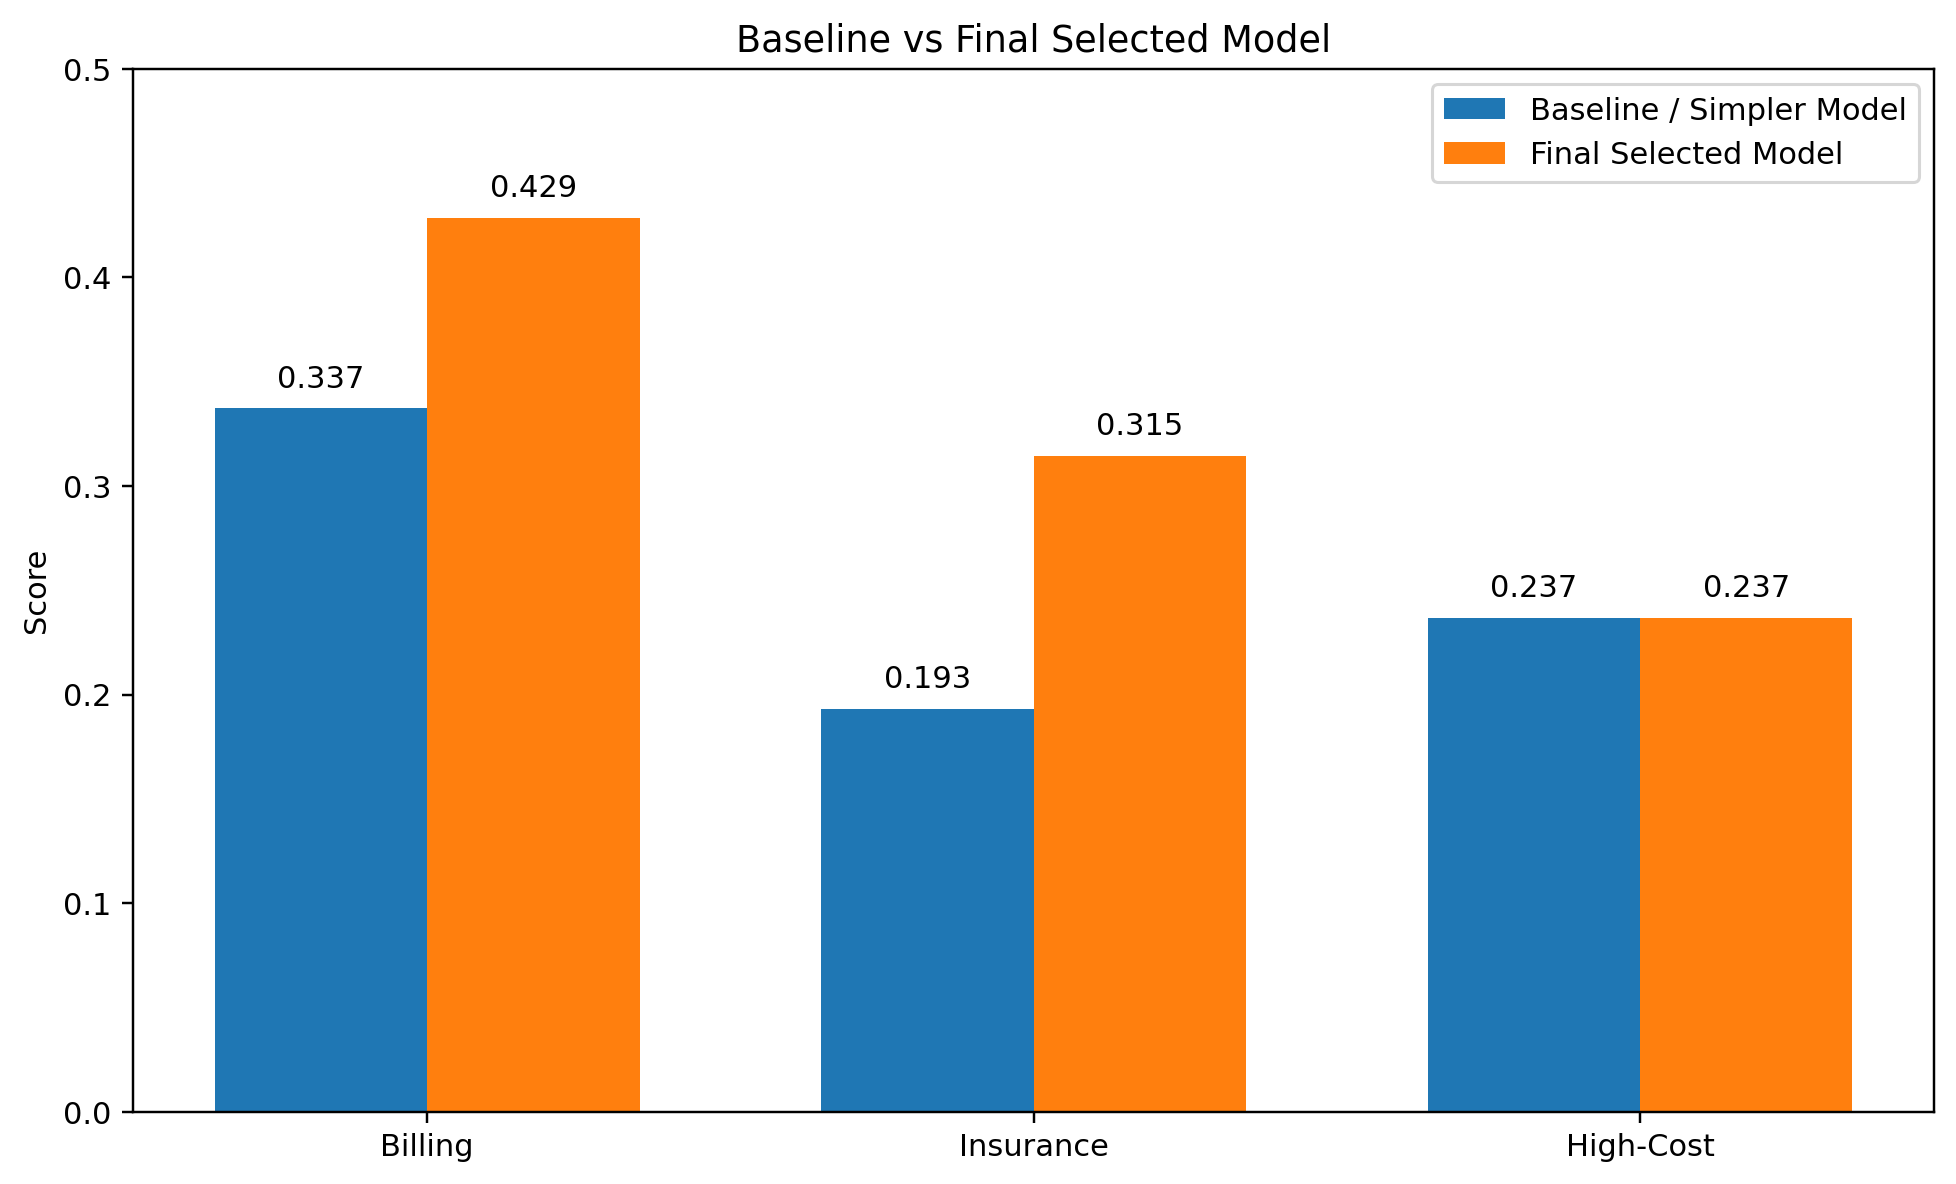

File: baseline_vs_final_selected.png


## 2. Billing Category Distribution


**What this shows**
- The billing target was converted into three categories: Low, Medium, and High.
- The classes are close to evenly distributed.

**How to talk about it**
- This is one reason billing category became a good classification target.
- It is more balanced and easier to interpret than raw billing amount regression.
    

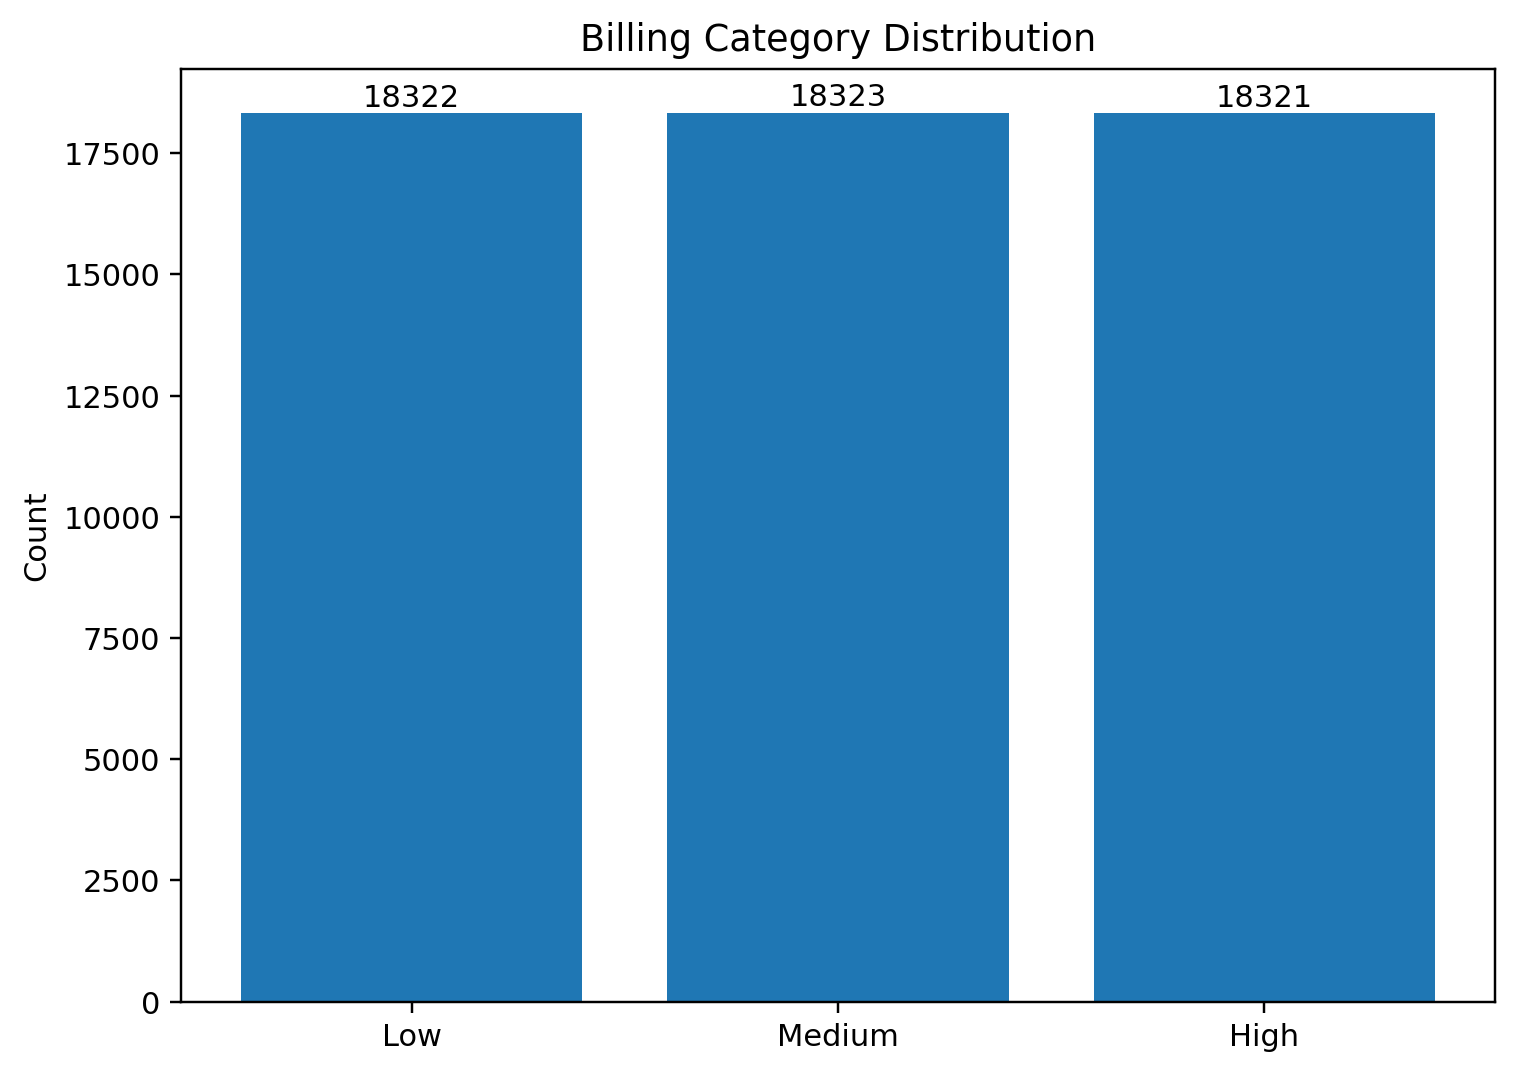

File: billing_category_distribution.png


## 3. Billing Category Model Comparison


**What this shows**
- Random Forest and Extra Trees clearly outperform Multinomial Logistic Regression.
- The strongest billing model is Random Forest.

**How to talk about it**
- Tree-based models captured more structure than the linear model.
- This confirmed that billing category classification was the strongest budget question.
    

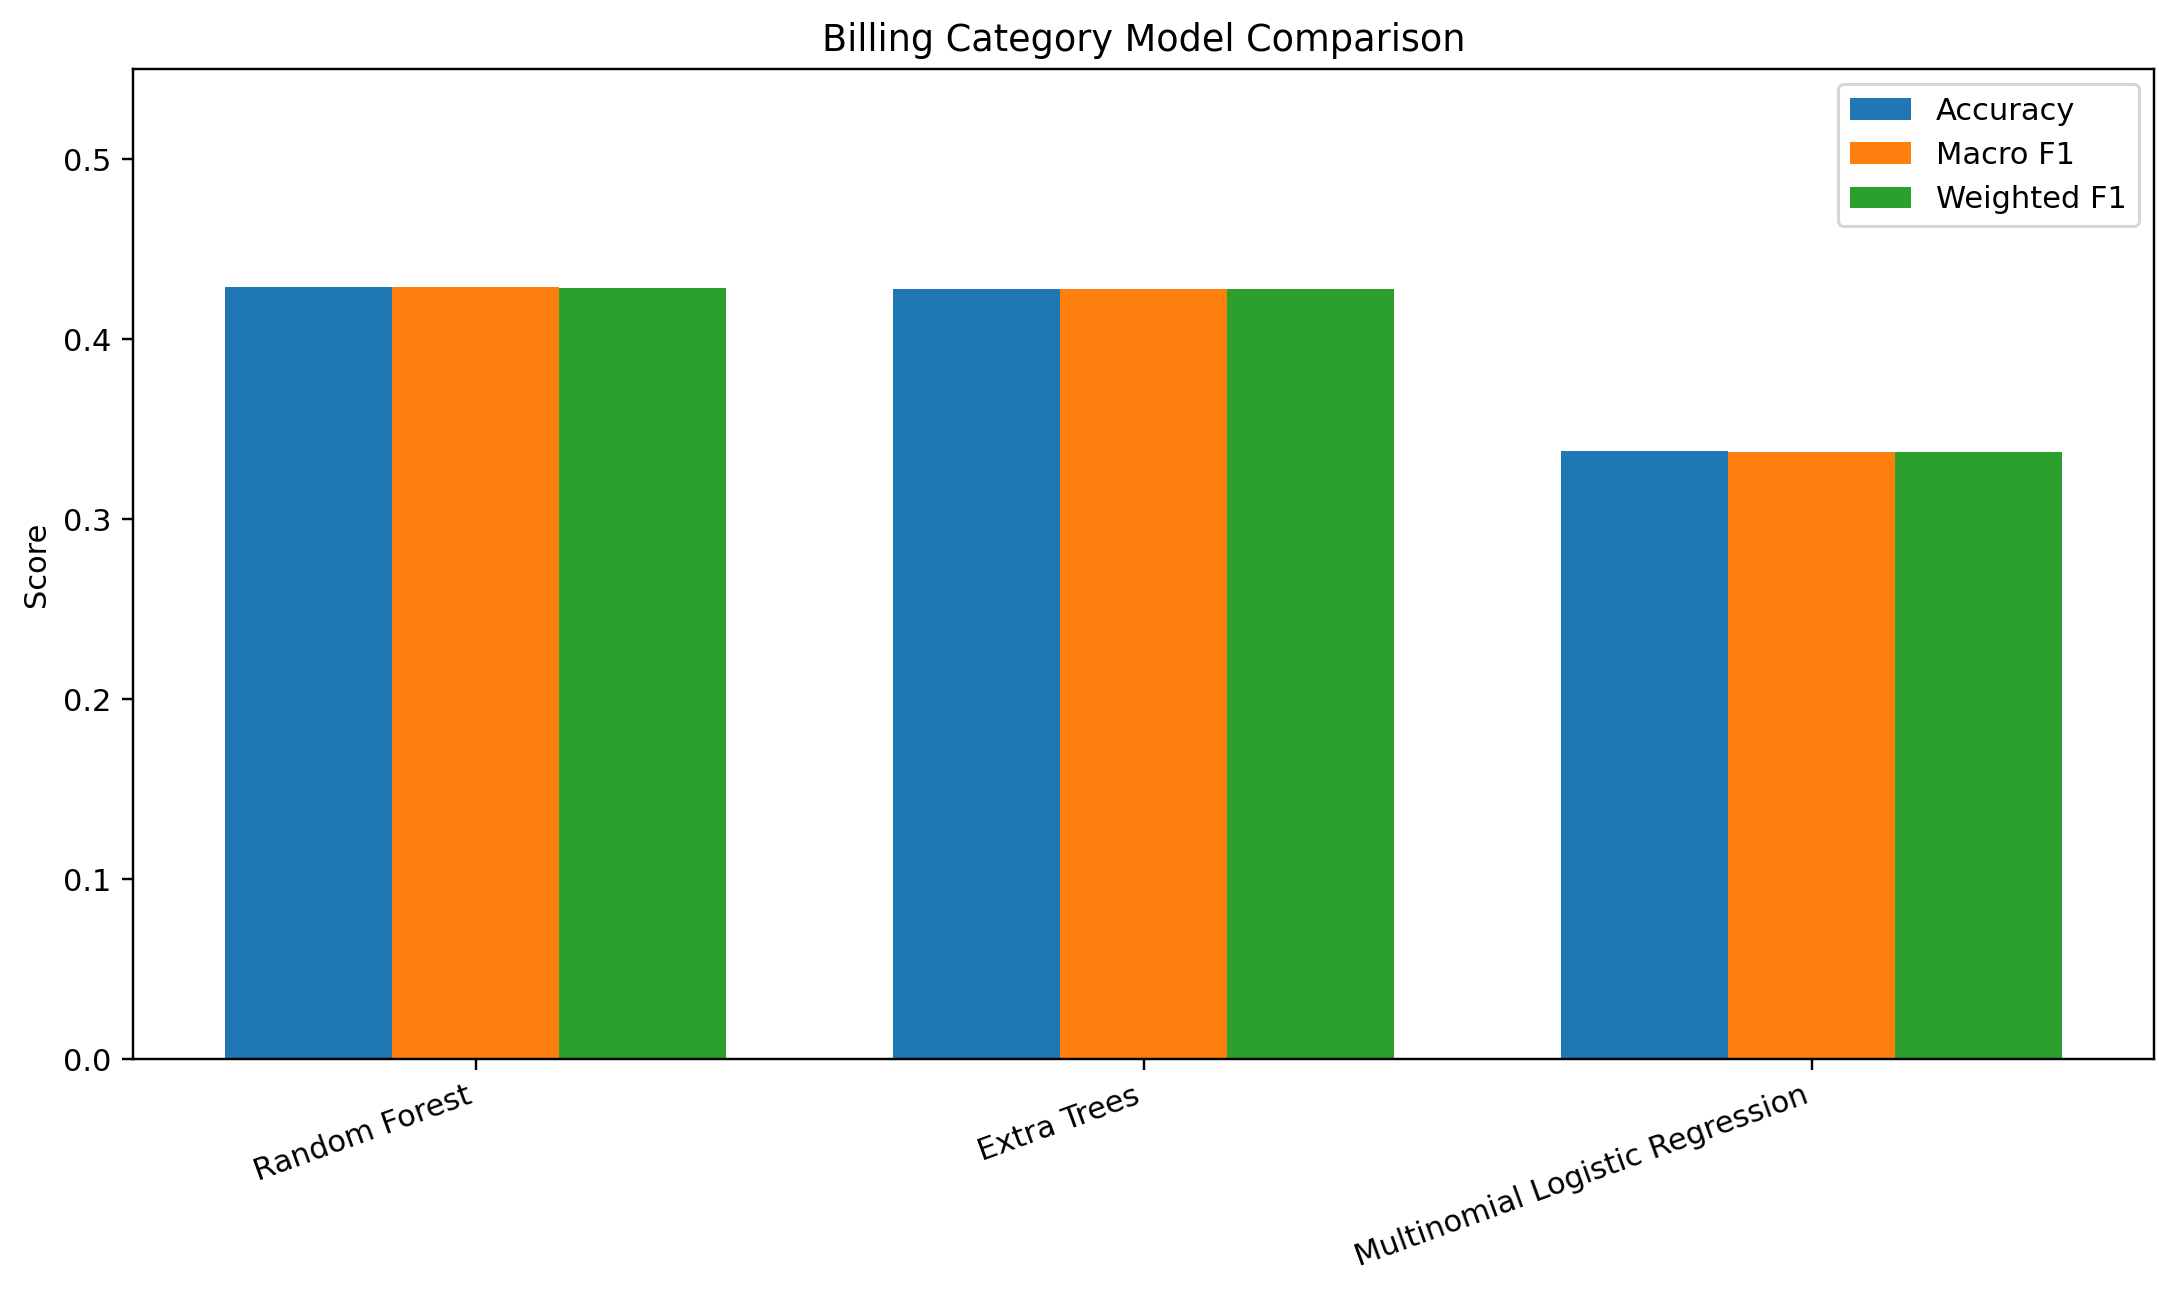

File: billing_model_comparison.png


## 4. Billing Category Confusion Matrix


**What this shows**
- Rows are true classes and columns are predicted classes.
- The model is learning meaningful separation across High, Low, and Medium billing categories.

**How to talk about it**
- This is one of the strongest visuals in the budget section.
- It shows that the model is not just achieving a score, but actually distinguishing the classes in a meaningful way.
    

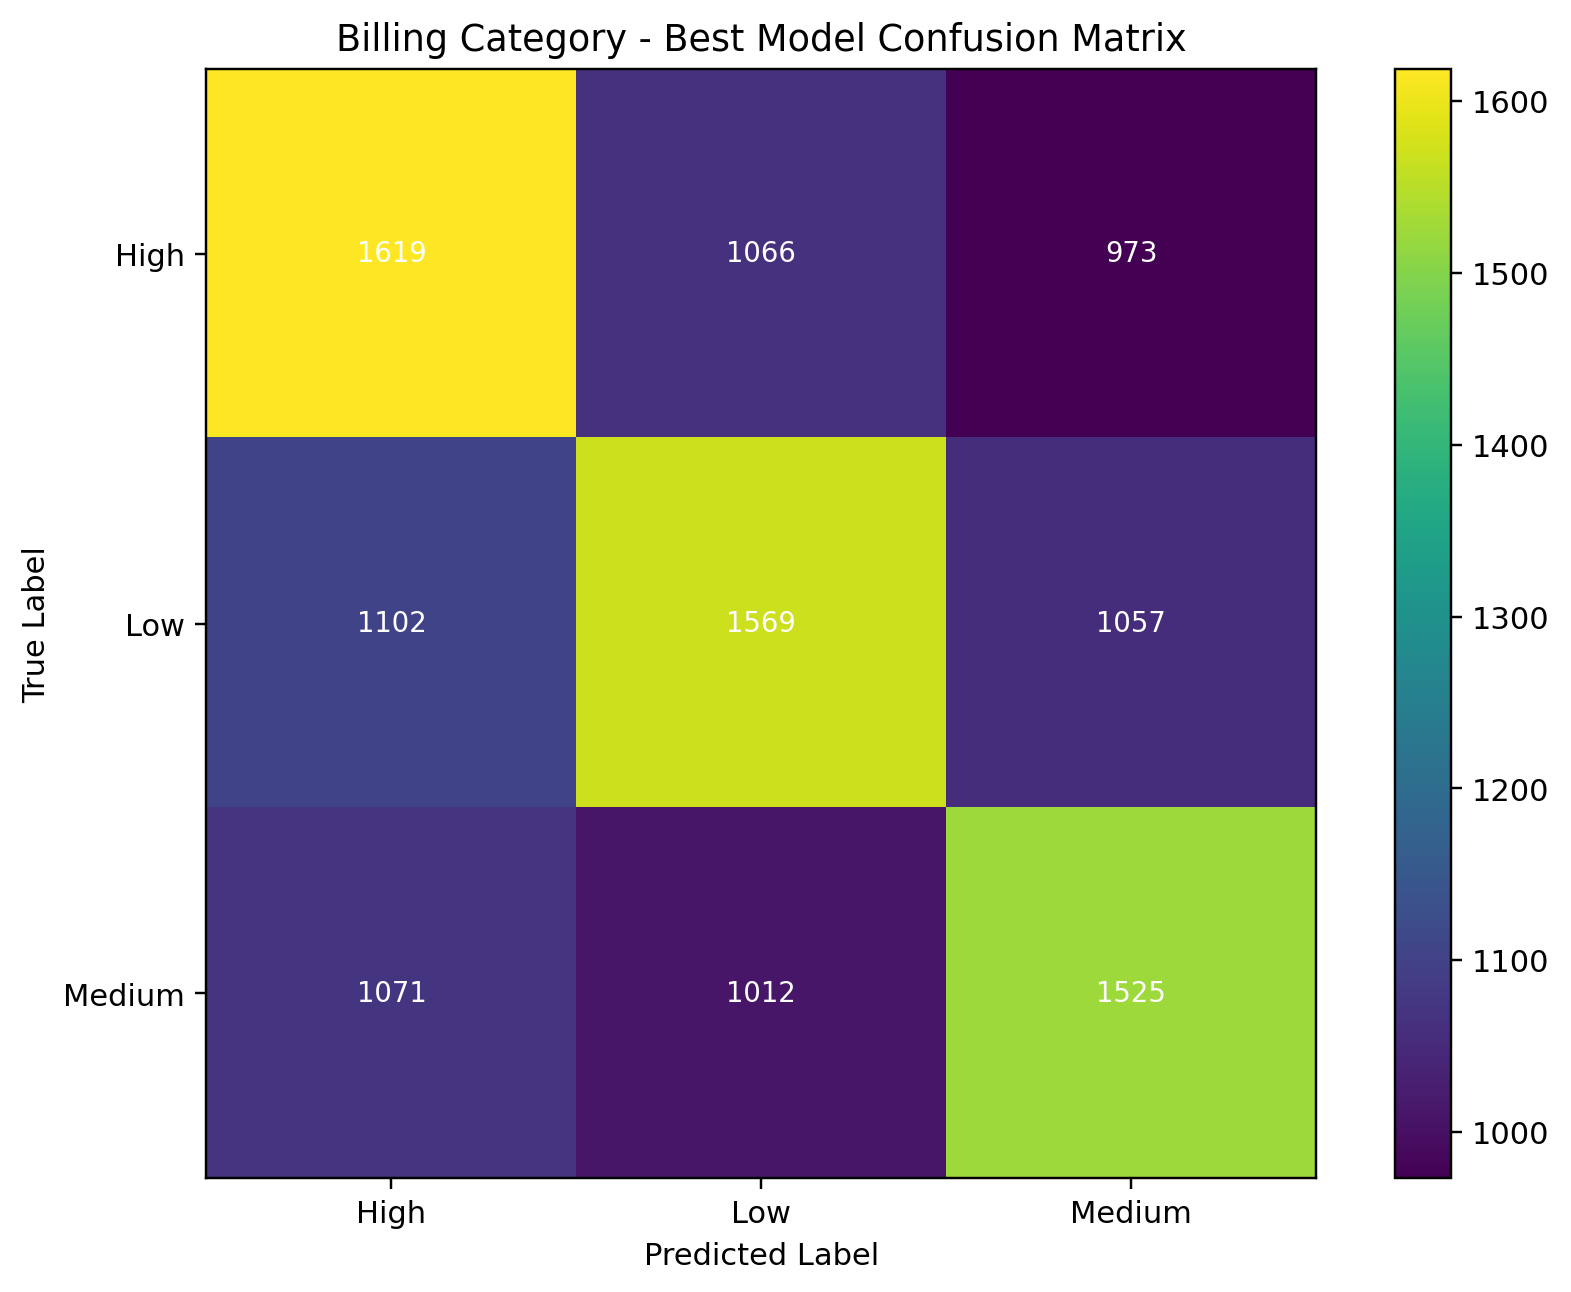

File: billing_confusion_matrix.png


## 5. Insurance Provider Distribution


**What this shows**
- The insurance-provider classes are fairly balanced.

**How to talk about it**
- The task is not dominated by a single provider class.
- That means the comparison is fairer and Macro F1 is a reasonable metric to use.
    

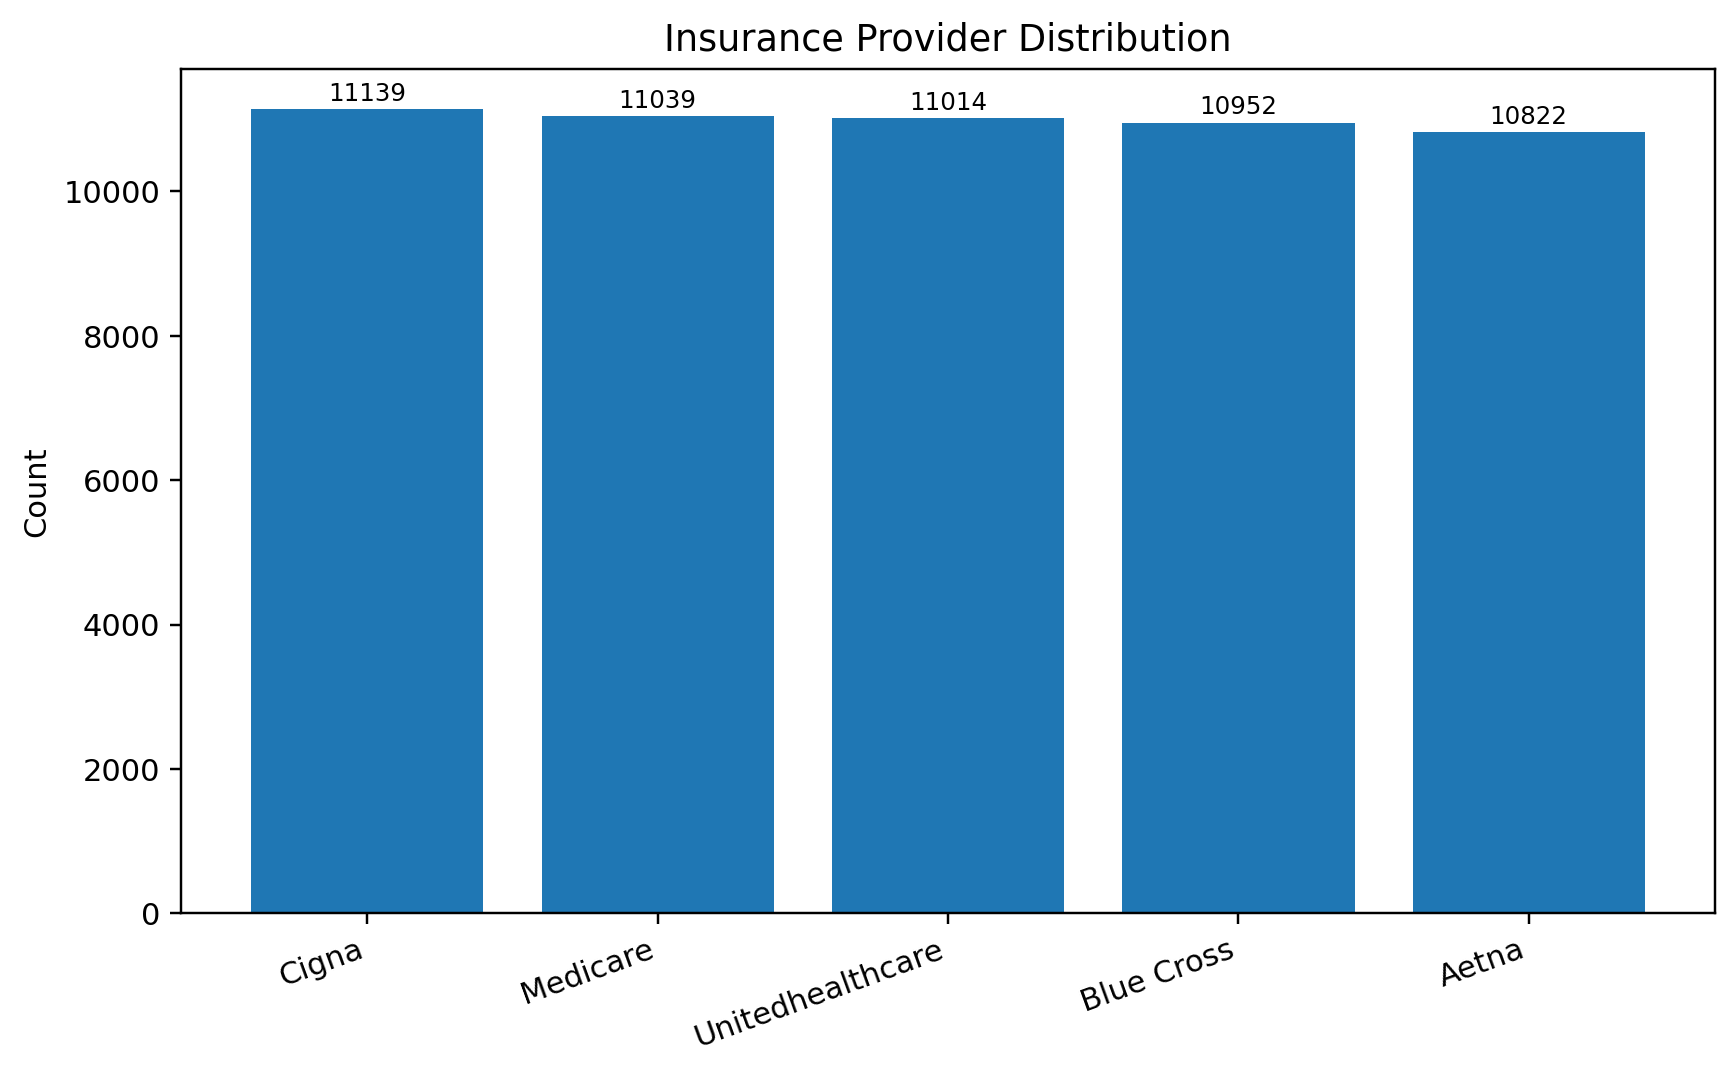

File: insurance_provider_distribution.png


## 6. Insurance Provider Model Comparison


**What this shows**
- Extra Trees and Random Forest perform better than Multinomial Logistic Regression.
- Extra Trees is the best final insurance model.

**How to talk about it**
- This task shows some signal, but it is clearly weaker than billing category.
- That is why insurance provider is kept as a secondary exploratory result.
    

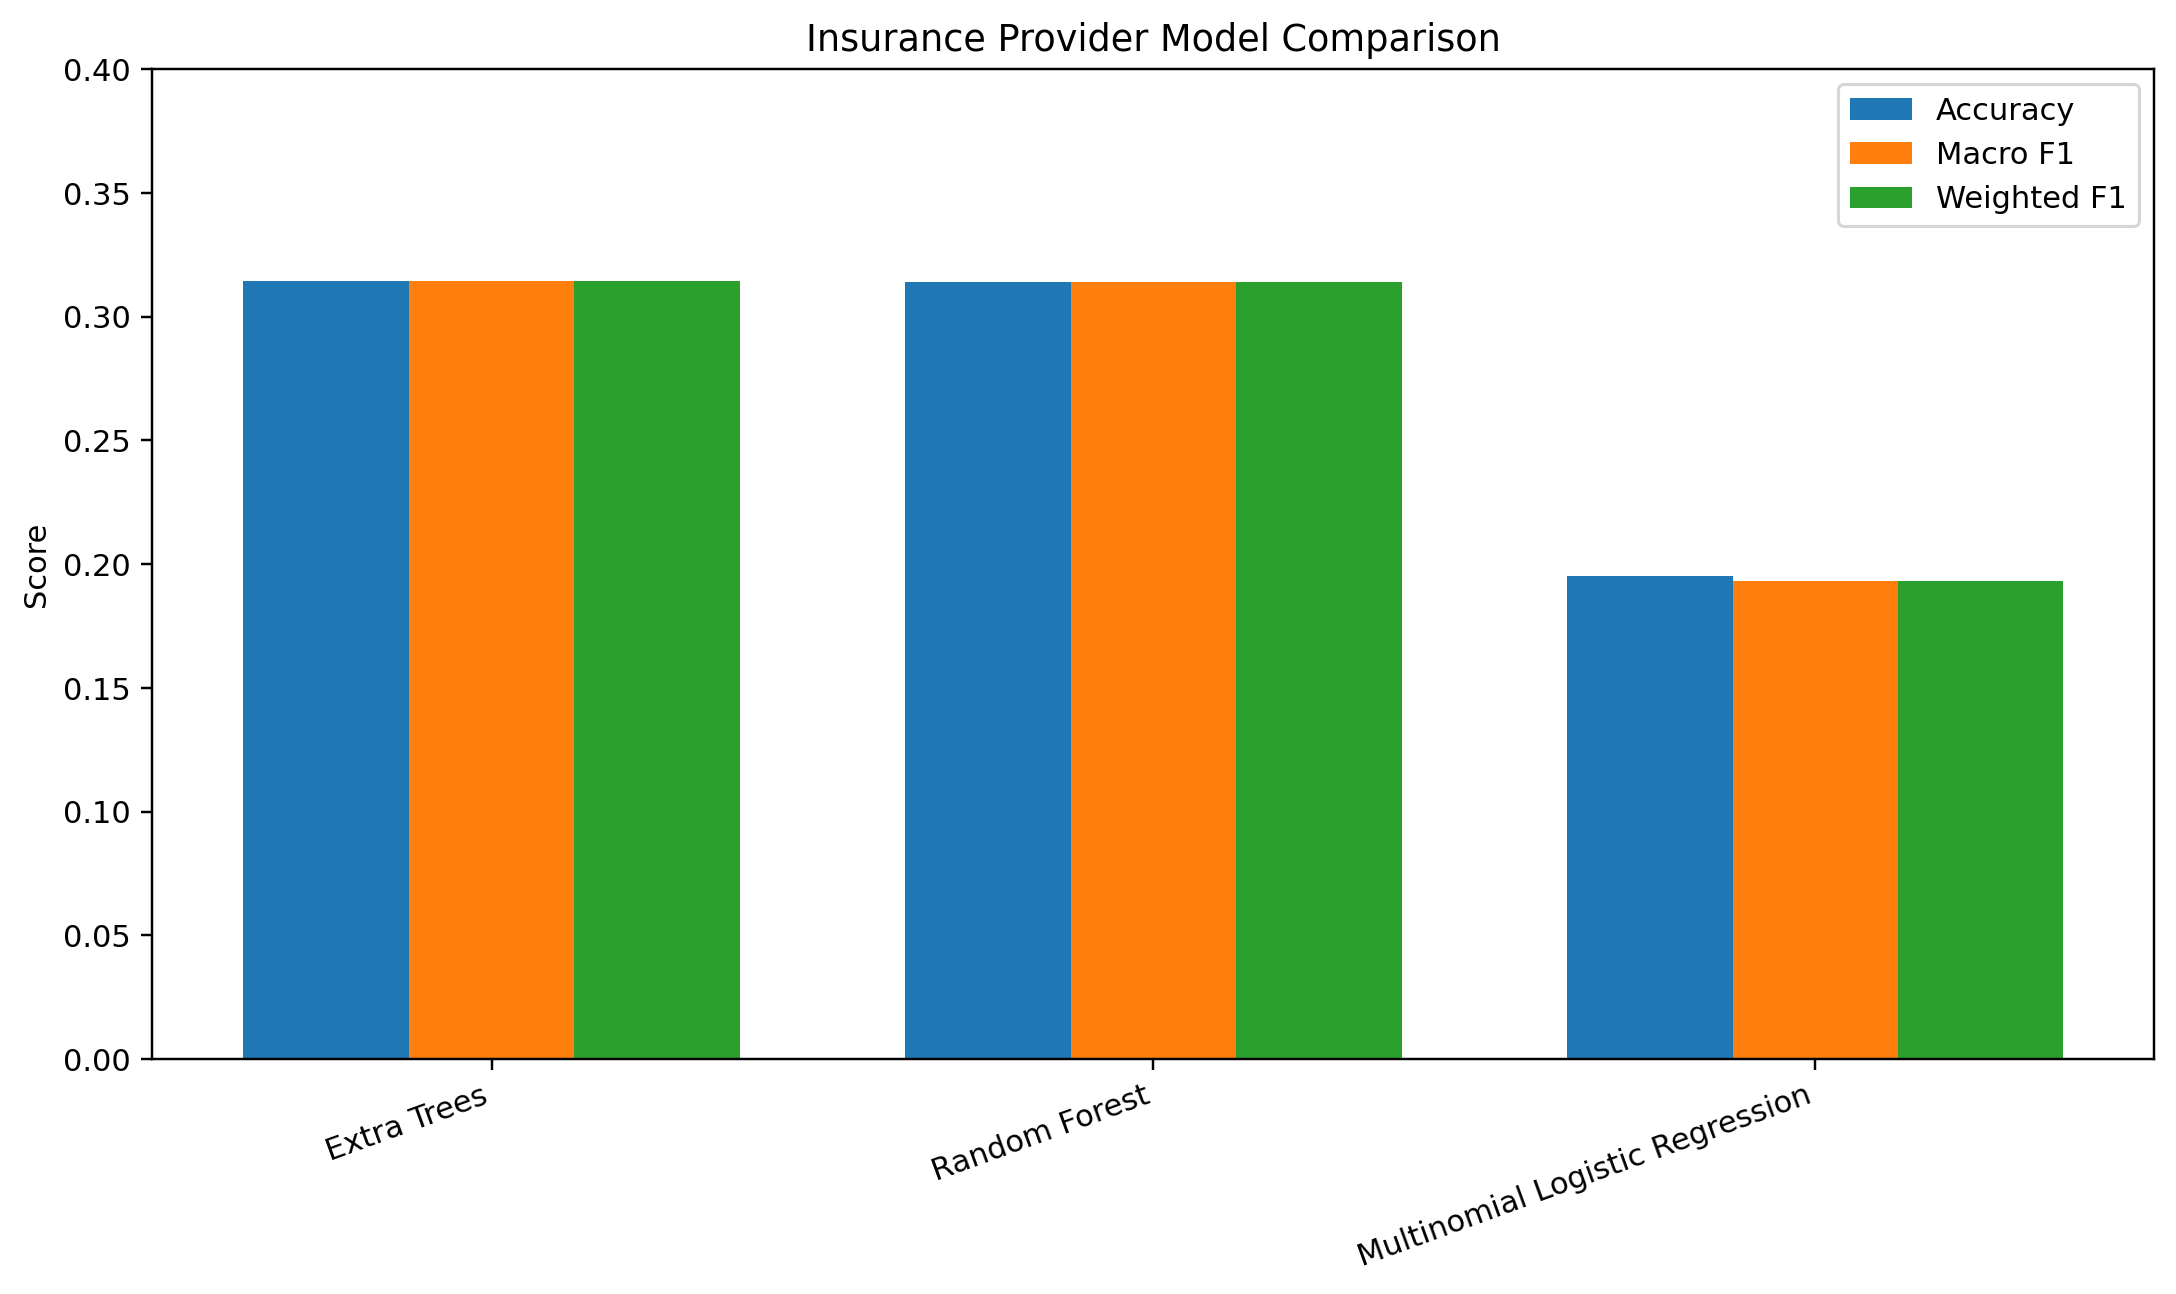

File: insurance_model_comparison.png


## 7. Insurance Provider Confusion Matrix


**What this shows**
- The model learns some structure across the five insurance-provider classes.
- However, the separation is weaker than what we saw for billing category.

**How to talk about it**
- This supports the decision to keep insurance provider in the presentation,
  but only as a secondary result rather than the headline finding.
    

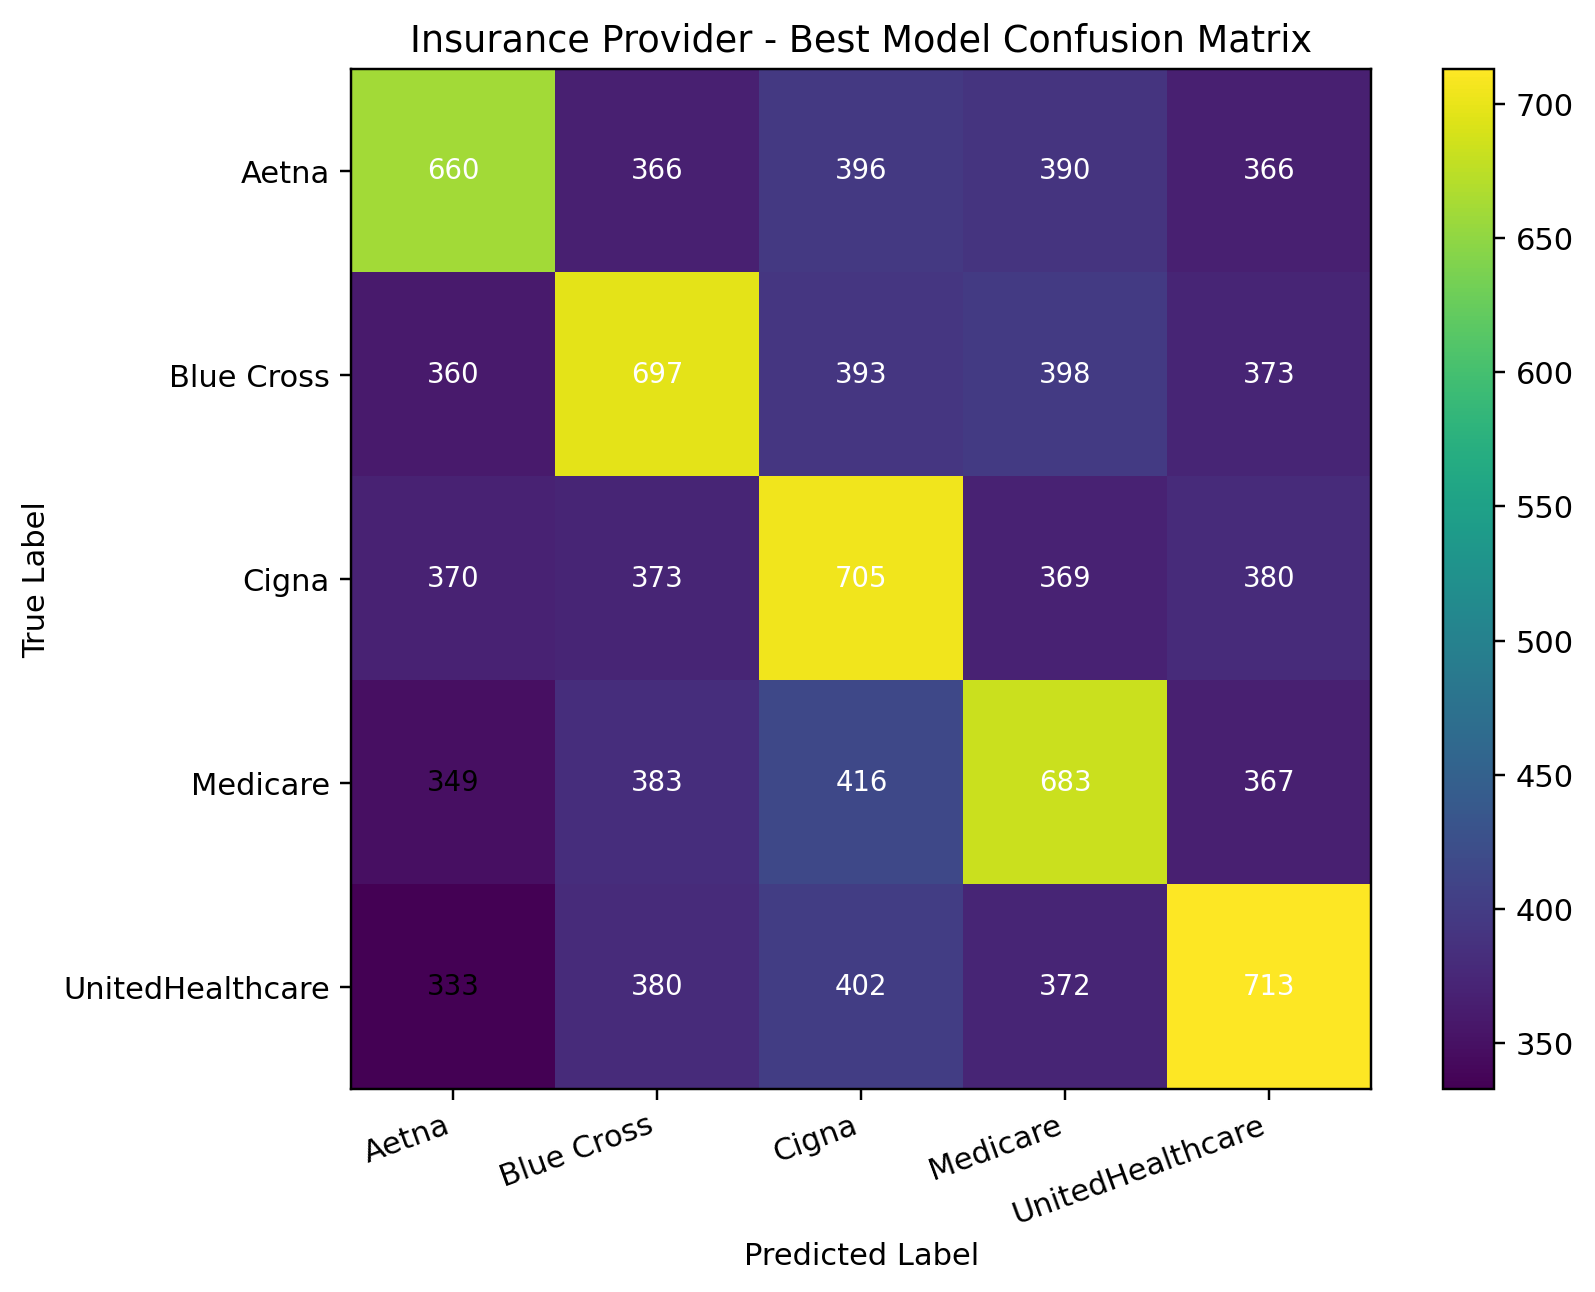

File: insurance_confusion_matrix.png


## 8. High-Cost Patient Distribution


**What this shows**
- High-cost patients are the minority class in the dataset.

**How to talk about it**
- This class imbalance is part of the reason the high-cost task was difficult.
- It also explains why accuracy alone is not a good metric here.
    

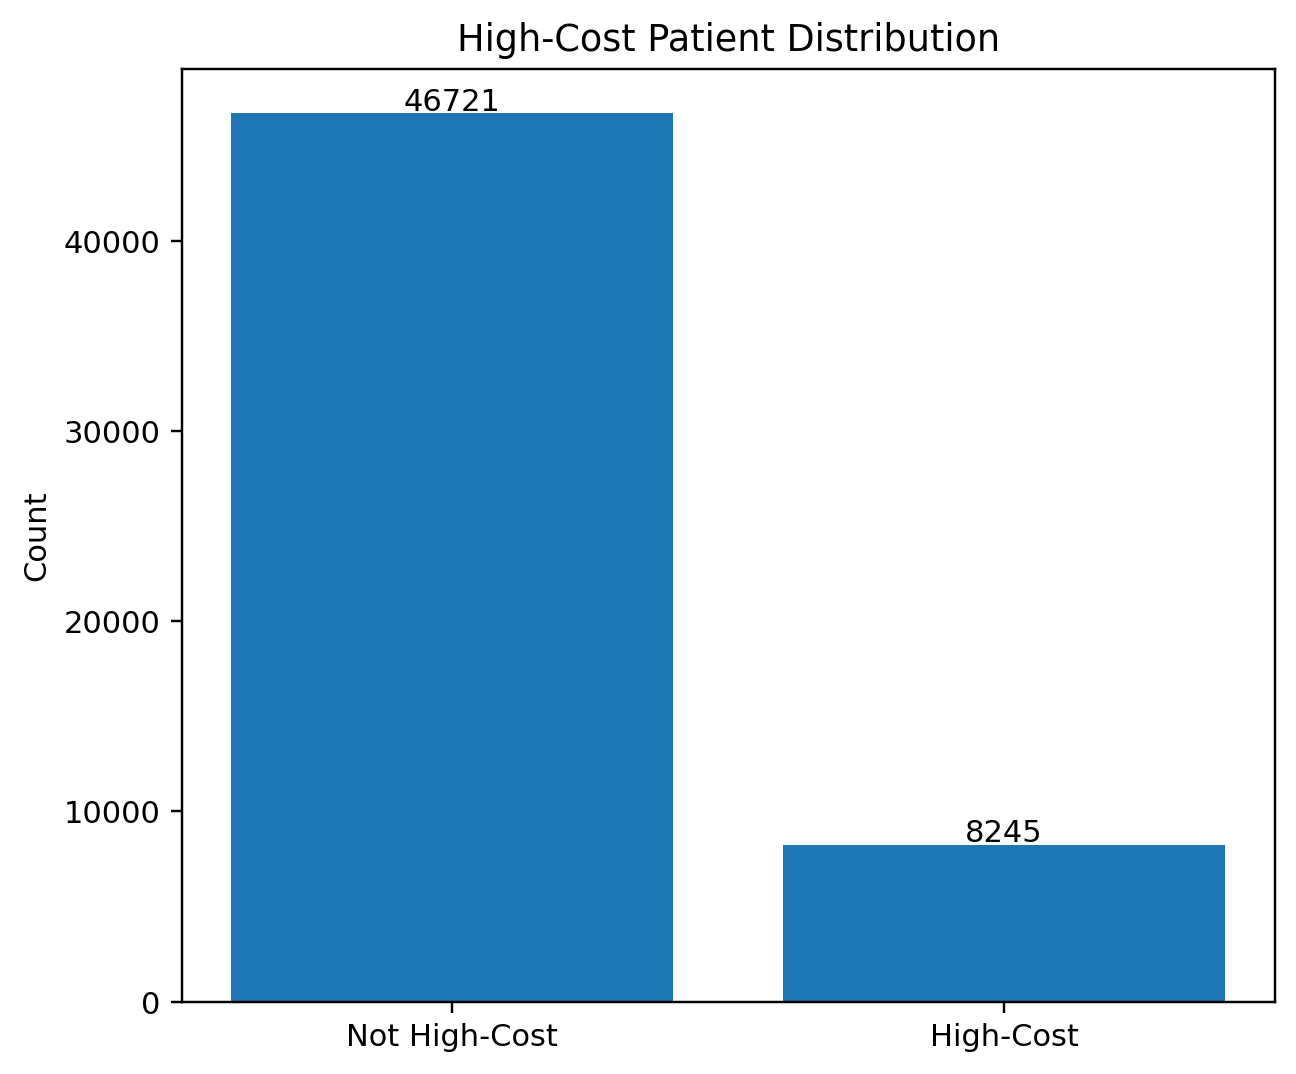

File: high_cost_distribution.png


## 9. High-Cost Patient Model Comparison


**What this shows**
- Logistic Regression Balanced has better recall, meaning it identifies more high-cost cases.
- Random Forest Balanced has very high precision, but misses many actual high-cost patients.
- Neither model gives a strong all-around result.

**How to talk about it**
- This is why high-cost is treated as a limitation.
- It was tested seriously, but the dataset did not support a strong final model.
    

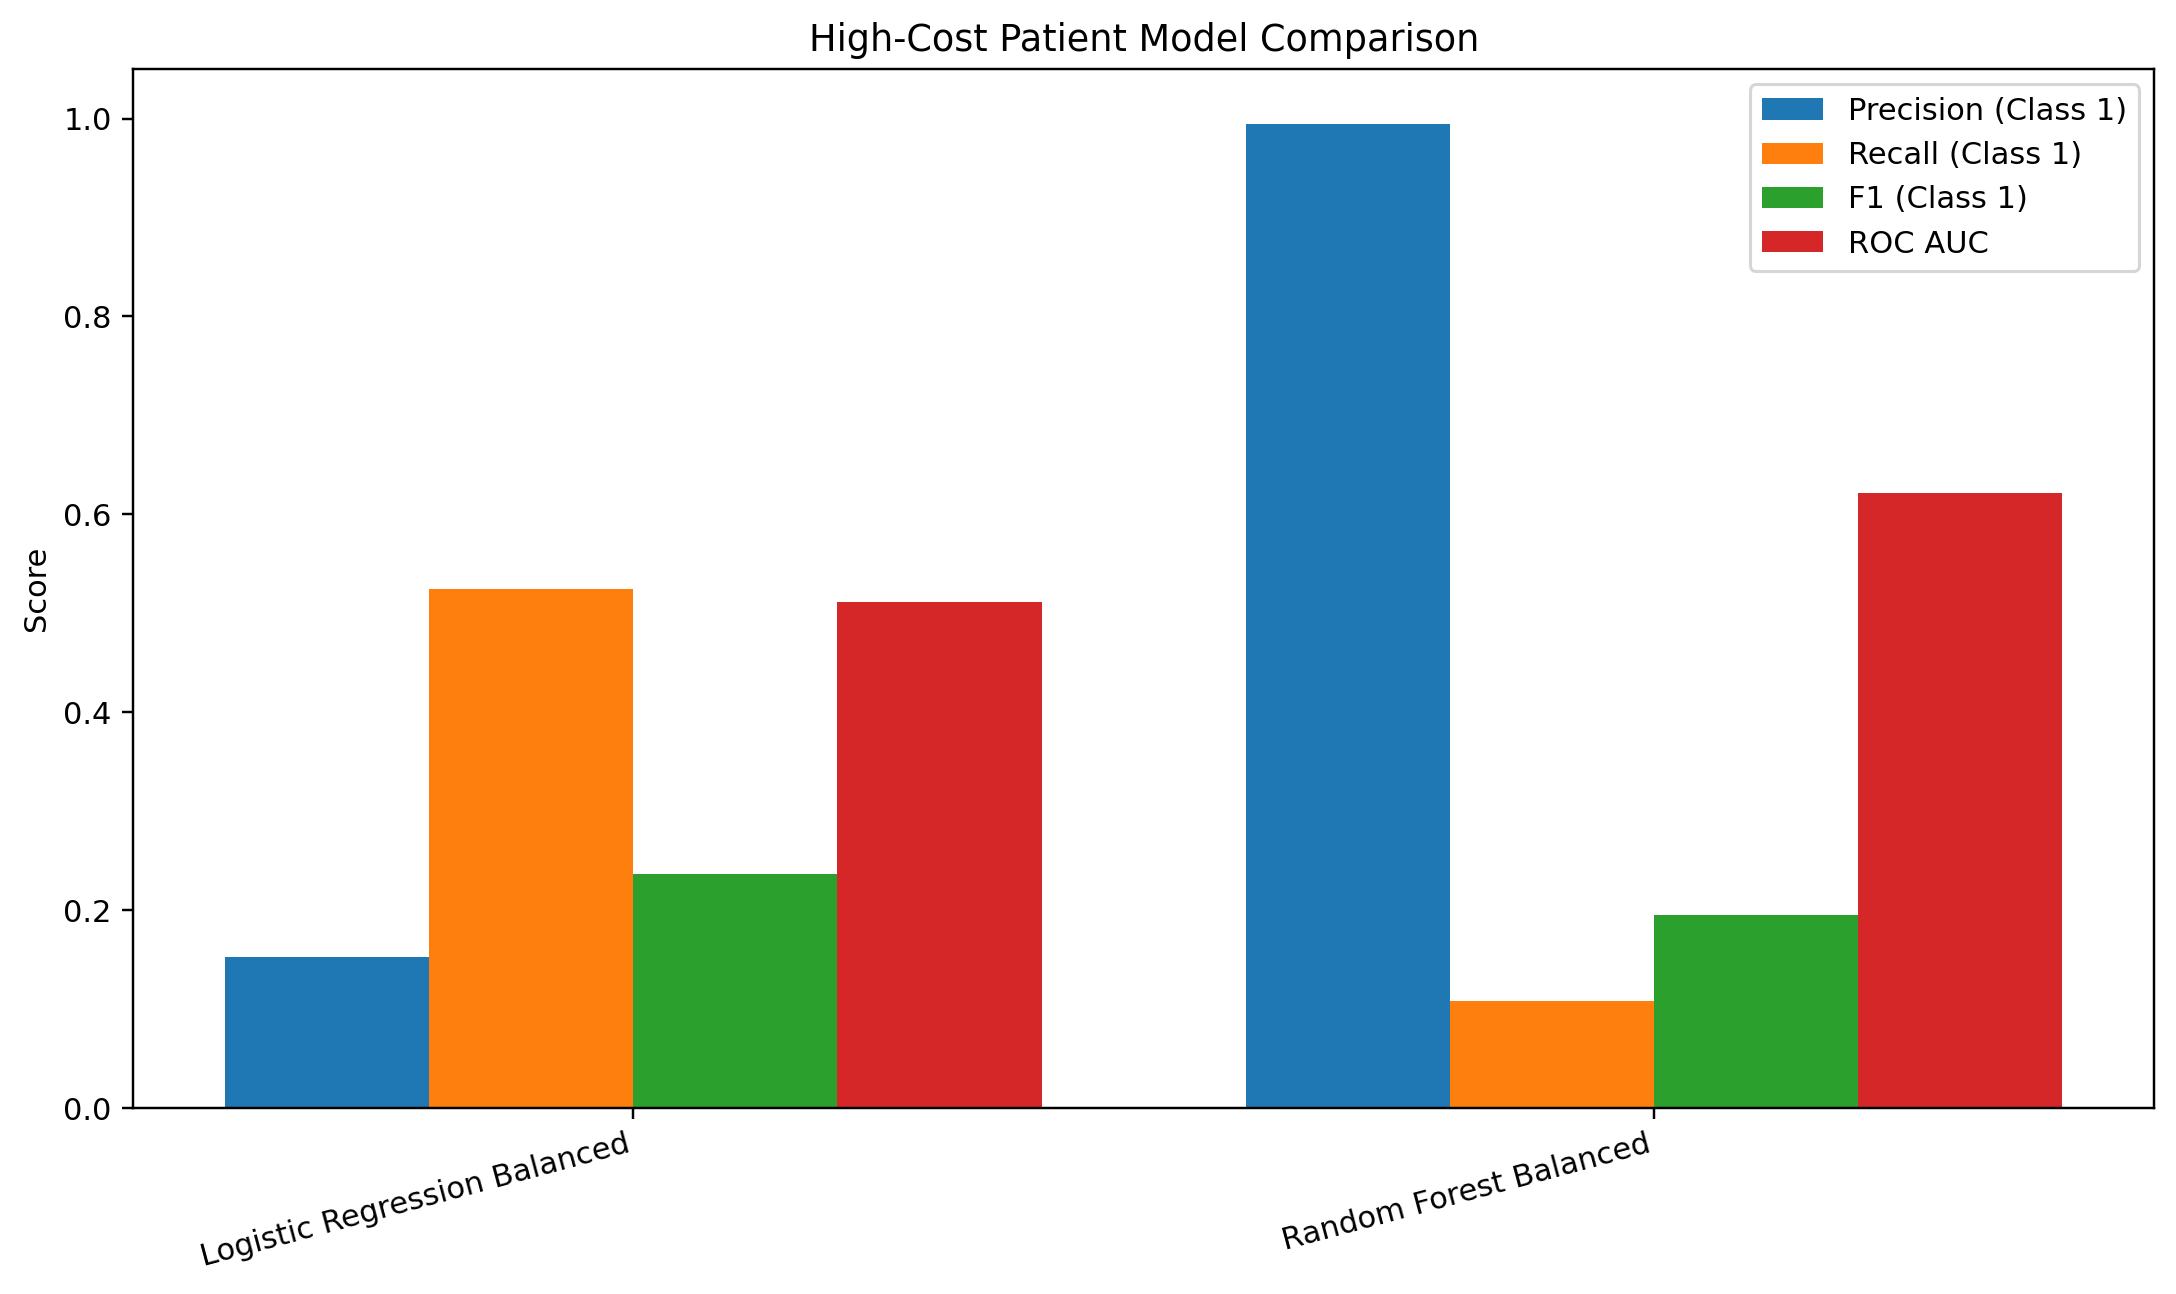

File: high_cost_model_comparison.png


## 10. High-Cost ROC AUC Comparison


**What this shows**
- Random Forest Balanced has stronger ROC AUC than Logistic Regression Balanced.
- But better class separation by AUC did not translate into a practically strong final result.

**How to talk about it**
- This is a useful limitation visual.
- It shows that even with better AUC, recall and F1 were still not strong enough for the task to be a main result.
    

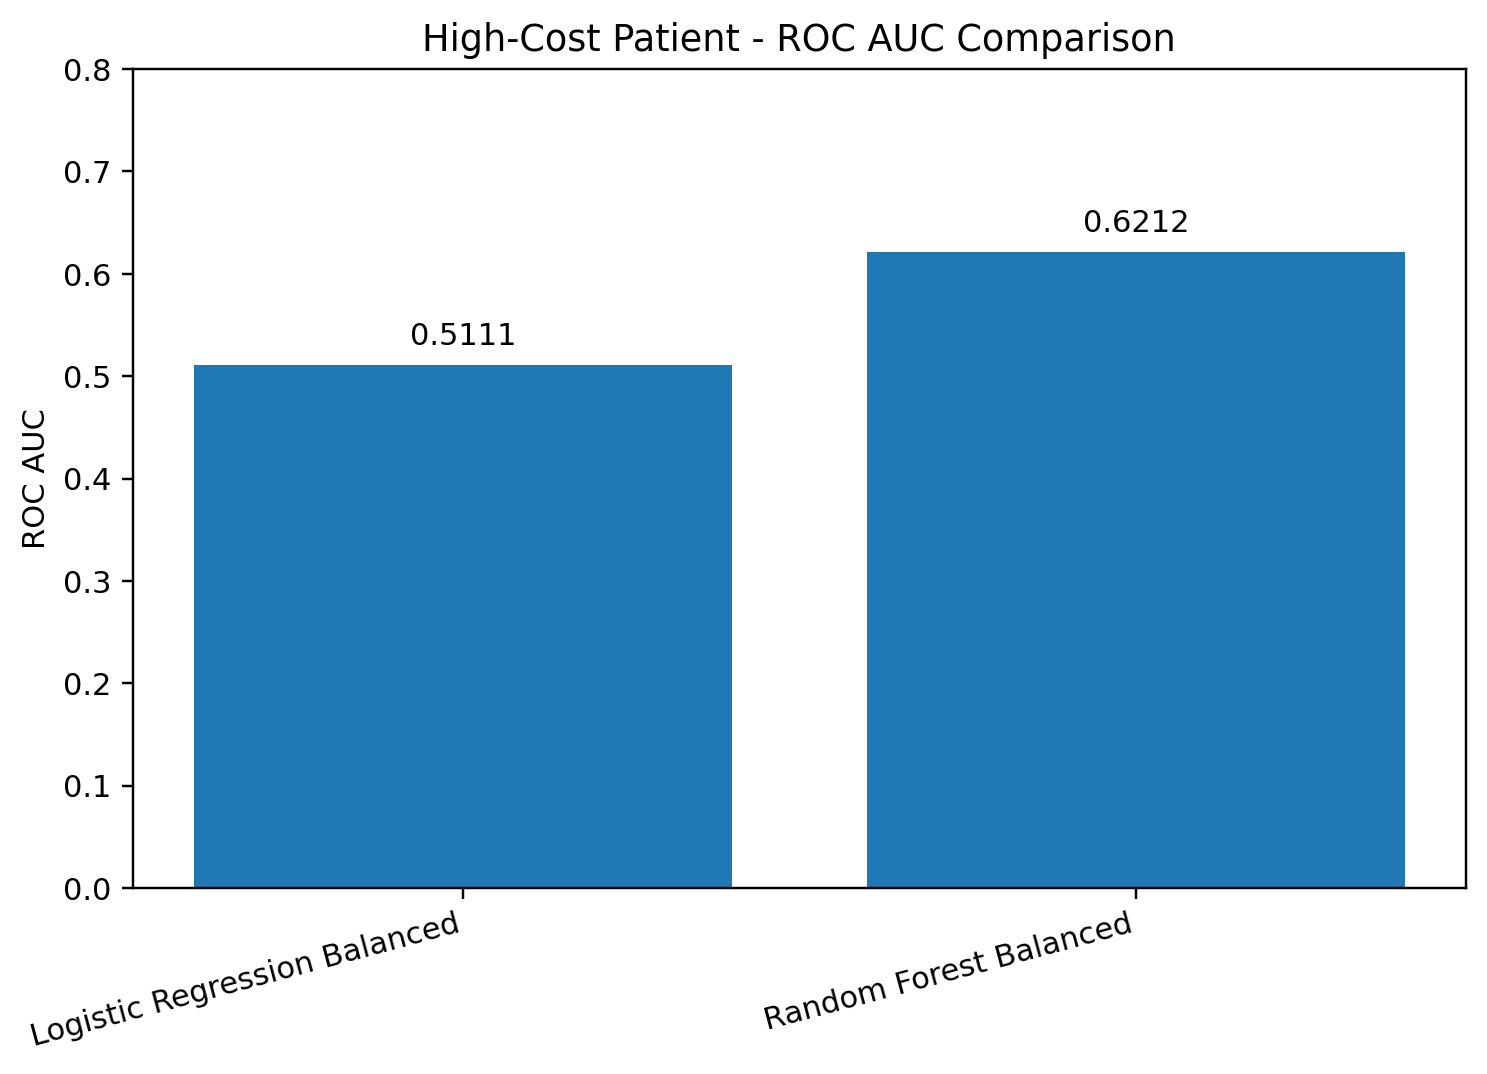

File: high_cost_auc_comparison.png


## 11. Hospital System Distribution


**What this shows**
- The added Hospital System feature is well balanced across the four groups.

**How to talk about it**
- This supports keeping hospital_system in the final preprocessing setup.
- It can capture broader hospital-level patterns without being dominated by one system.
    

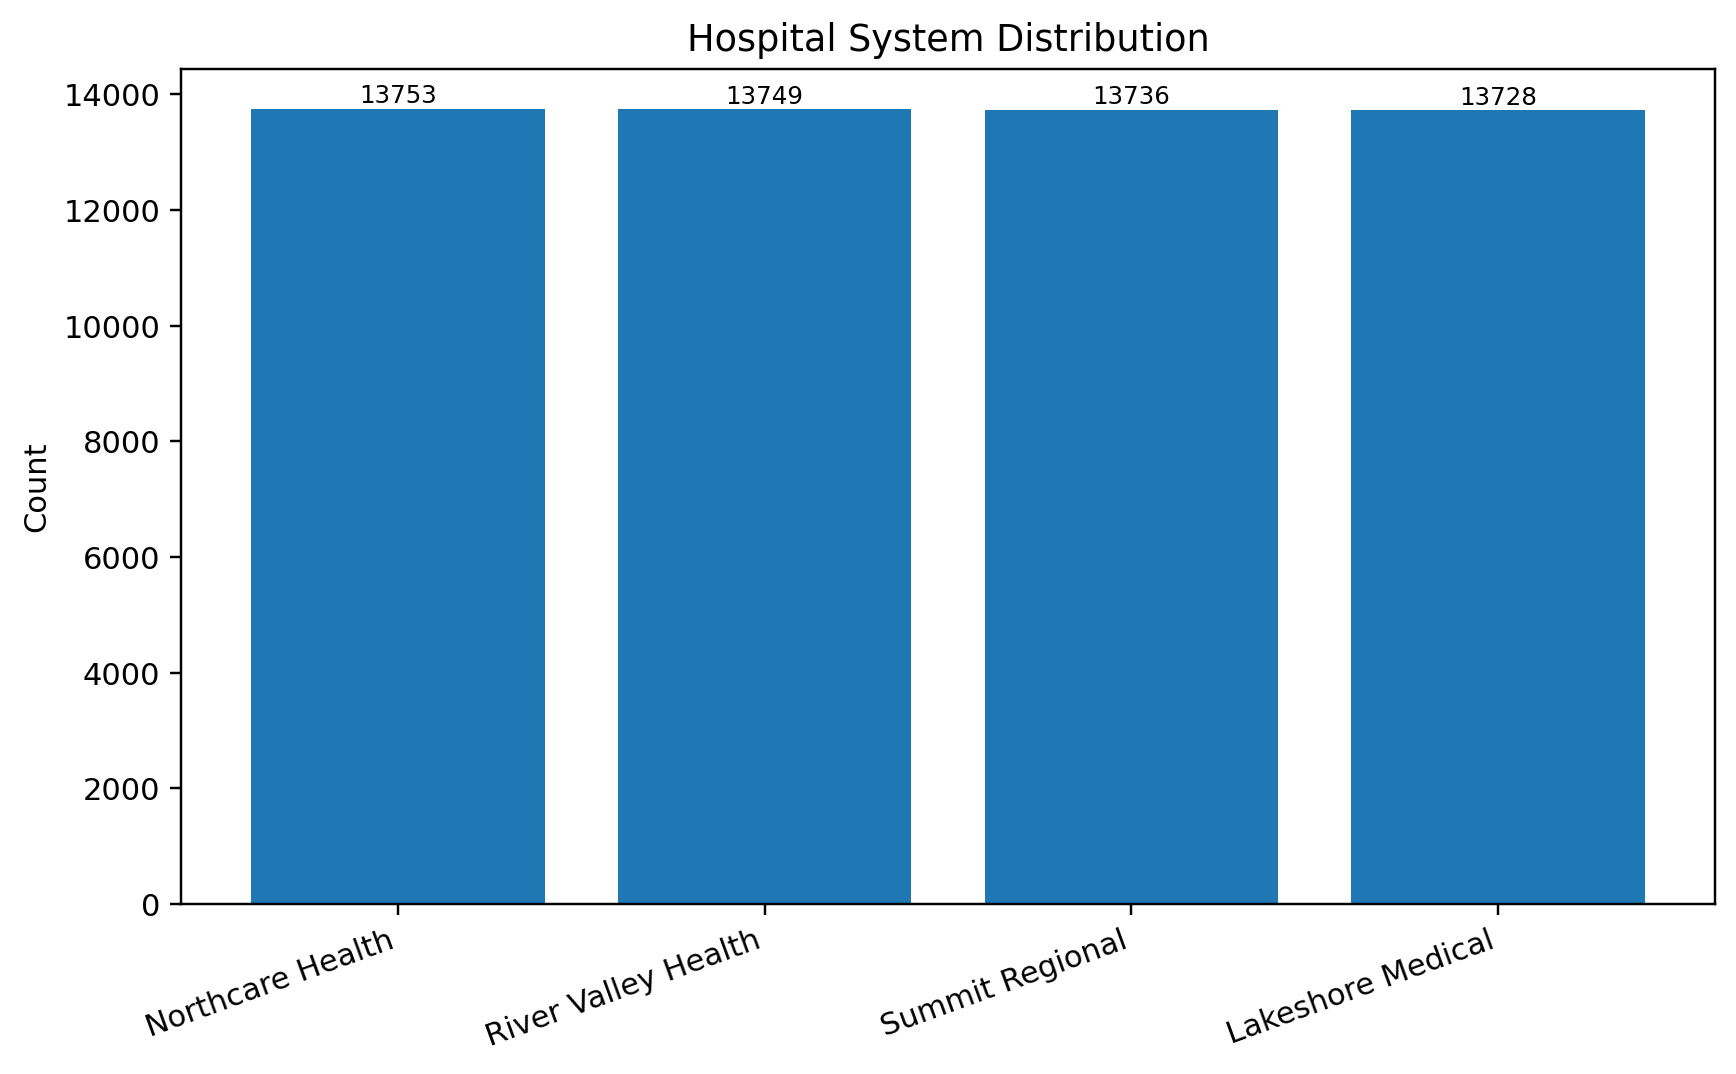

File: hospital_system_distribution.png


## 12. Final Selected Results Overview


**What this shows**
- Billing category is the strongest final result.
- Insurance provider is weaker, but still usable as a secondary exploratory result.
- High-cost remains the weakest and should be presented as a limitation.

**How to talk about it**
- This is a good final conclusion visual.
- It summarizes the final budget subgroup story in one chart.
    

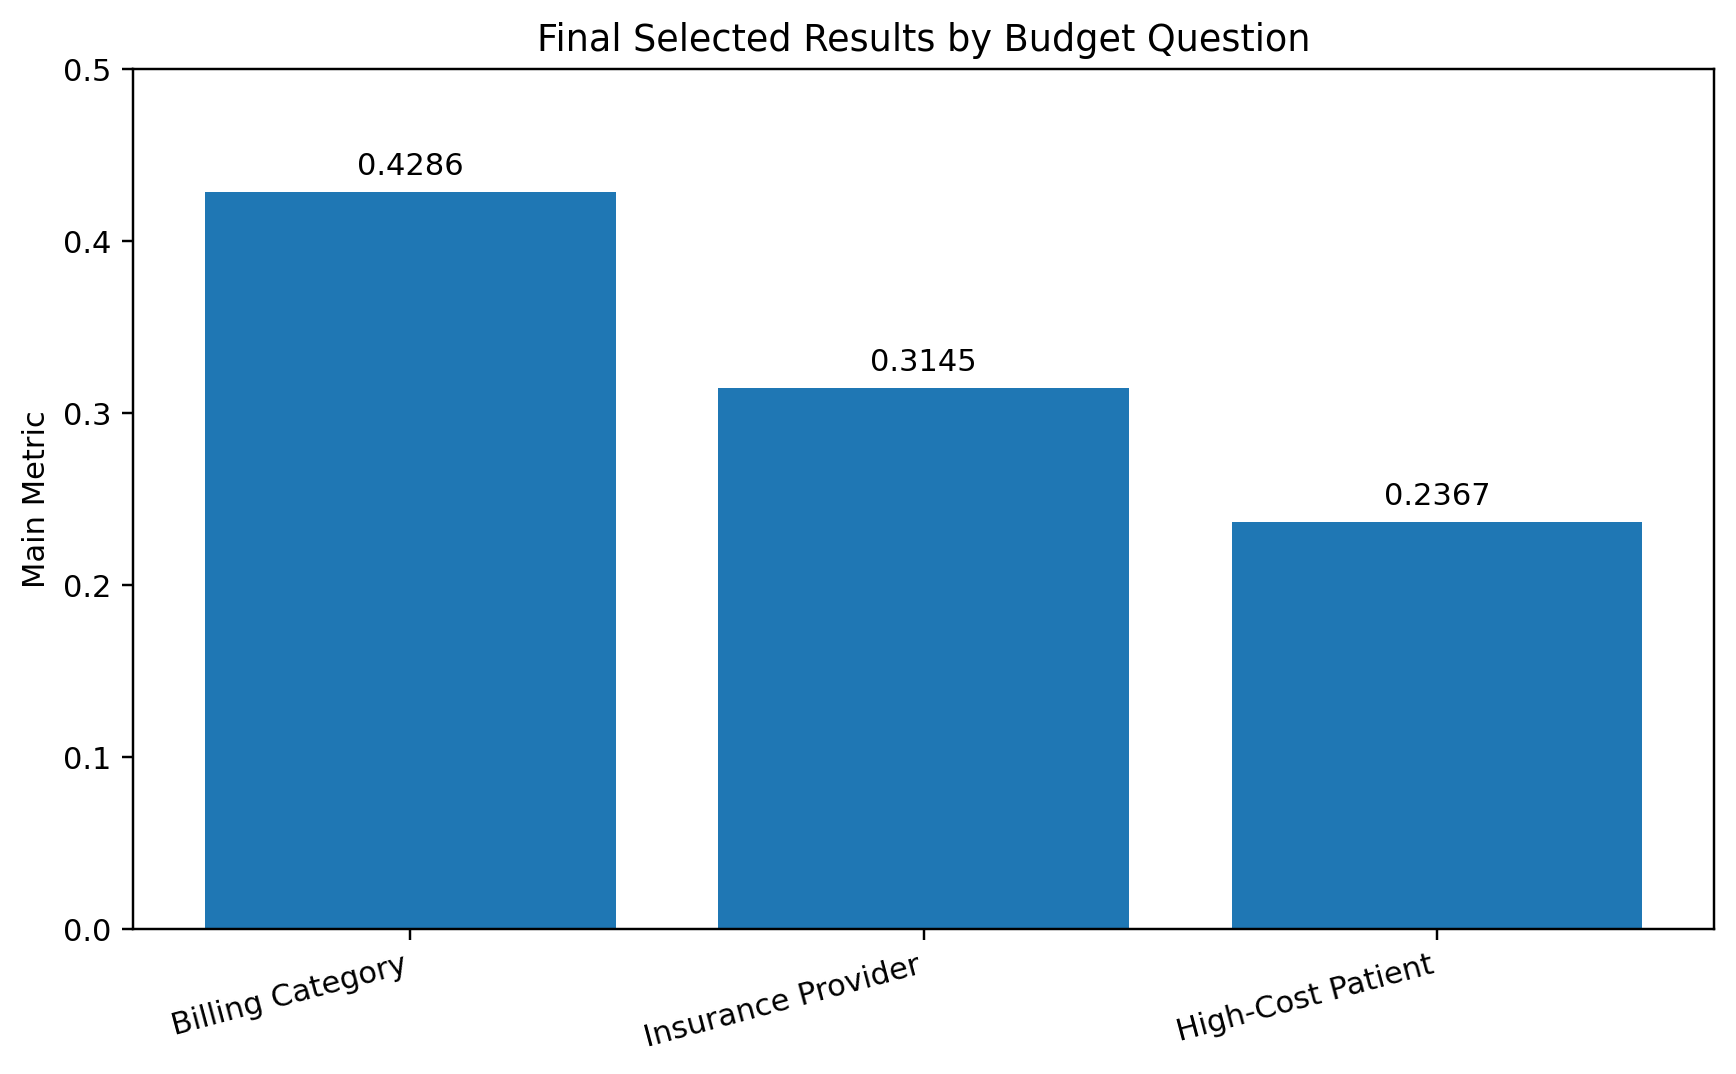

File: final_selected_results_overview.png


## Final Note


These visuals together are enough to support:
- a baseline slide,
- a billing result slide,
- an insurance result slide,
- a limitation slide for high-cost,
- and a final conclusion slide.

Recommended visuals for the deck:
1. **baseline_vs_final_selected.png** → new baseline slide  
2. **billing_confusion_matrix.png** → billing result slide  
3. **insurance_confusion_matrix.png** → insurance result slide  
4. **high_cost_auc_comparison.png** → high-cost limitation slide  
5. **final_selected_results_overview.png** → conclusion slide  


In [ ]:
# ============================================================
# THIRD CELL: VIEW AND EXPLAIN CREATED VISUALS
# Run this after the visualization-generation cell
# ============================================================

from pathlib import Path
from IPython.display import display, Markdown, Image

vis_dir = Path("presentation_visuals")

print("Reading visuals from:", vis_dir.resolve())

def show_visual(title, explanation, filename, width=950):
    path = vis_dir / filename
    display(Markdown(f"## {title}"))
    display(Markdown(explanation))
    if path.exists():
        display(Image(filename=str(path), width=width))
        print("File:", path.name)
    else:
        print("Missing file:", path)

# ------------------------------------------------------------
# 1) Baseline vs final selected
# ------------------------------------------------------------
show_visual(
    "1. Baseline vs Final Selected Model",
    """
**What this shows**
- This compares a simpler baseline model against the final selected model for each budget question.
- Billing and insurance improved meaningfully after better framing and preprocessing.
- High-cost stayed weak, which supports why it is treated as a limitation.

**How to talk about it**
- Billing category improved after changing from raw regression to classification.
- Insurance provider also improved, but less strongly.
- High-cost did not improve enough to become a main result.
    """,
    "baseline_vs_final_selected.png"
)

# ------------------------------------------------------------
# 2) Billing category distribution
# ------------------------------------------------------------
show_visual(
    "2. Billing Category Distribution",
    """
**What this shows**
- The billing target was converted into three categories: Low, Medium, and High.
- The classes are close to evenly distributed.

**How to talk about it**
- This is one reason billing category became a good classification target.
- It is more balanced and easier to interpret than raw billing amount regression.
    """,
    "billing_category_distribution.png"
)

# ------------------------------------------------------------
# 3) Billing model comparison
# ------------------------------------------------------------
show_visual(
    "3. Billing Category Model Comparison",
    """
**What this shows**
- Random Forest and Extra Trees clearly outperform Multinomial Logistic Regression.
- The strongest billing model is Random Forest.

**How to talk about it**
- Tree-based models captured more structure than the linear model.
- This confirmed that billing category classification was the strongest budget question.
    """,
    "billing_model_comparison.png"
)

# ------------------------------------------------------------
# 4) Billing confusion matrix
# ------------------------------------------------------------
show_visual(
    "4. Billing Category Confusion Matrix",
    """
**What this shows**
- Rows are true classes and columns are predicted classes.
- The model is learning meaningful separation across High, Low, and Medium billing categories.

**How to talk about it**
- This is one of the strongest visuals in the budget section.
- It shows that the model is not just achieving a score, but actually distinguishing the classes in a meaningful way.
    """,
    "billing_confusion_matrix.png"
)

# ------------------------------------------------------------
# 5) Insurance provider distribution
# ------------------------------------------------------------
show_visual(
    "5. Insurance Provider Distribution",
    """
**What this shows**
- The insurance-provider classes are fairly balanced.

**How to talk about it**
- The task is not dominated by a single provider class.
- That means the comparison is fairer and Macro F1 is a reasonable metric to use.
    """,
    "insurance_provider_distribution.png"
)

# ------------------------------------------------------------
# 6) Insurance model comparison
# ------------------------------------------------------------
show_visual(
    "6. Insurance Provider Model Comparison",
    """
**What this shows**
- Extra Trees and Random Forest perform better than Multinomial Logistic Regression.
- Extra Trees is the best final insurance model.

**How to talk about it**
- This task shows some signal, but it is clearly weaker than billing category.
- That is why insurance provider is kept as a secondary exploratory result.
    """,
    "insurance_model_comparison.png"
)

# ------------------------------------------------------------
# 7) Insurance confusion matrix
# ------------------------------------------------------------
show_visual(
    "7. Insurance Provider Confusion Matrix",
    """
**What this shows**
- The model learns some structure across the five insurance-provider classes.
- However, the separation is weaker than what we saw for billing category.

**How to talk about it**
- This supports the decision to keep insurance provider in the presentation,
  but only as a secondary result rather than the headline finding.
    """,
    "insurance_confusion_matrix.png"
)

# ------------------------------------------------------------
# 8) High-cost distribution
# ------------------------------------------------------------
show_visual(
    "8. High-Cost Patient Distribution",
    """
**What this shows**
- High-cost patients are the minority class in the dataset.

**How to talk about it**
- This class imbalance is part of the reason the high-cost task was difficult.
- It also explains why accuracy alone is not a good metric here.
    """,
    "high_cost_distribution.png"
)

# ------------------------------------------------------------
# 9) High-cost model comparison
# ------------------------------------------------------------
show_visual(
    "9. High-Cost Patient Model Comparison",
    """
**What this shows**
- Logistic Regression Balanced has better recall, meaning it identifies more high-cost cases.
- Random Forest Balanced has very high precision, but misses many actual high-cost patients.
- Neither model gives a strong all-around result.

**How to talk about it**
- This is why high-cost is treated as a limitation.
- It was tested seriously, but the dataset did not support a strong final model.
    """,
    "high_cost_model_comparison.png"
)

# ------------------------------------------------------------
# 10) High-cost AUC comparison
# ------------------------------------------------------------
show_visual(
    "10. High-Cost ROC AUC Comparison",
    """
**What this shows**
- Random Forest Balanced has stronger ROC AUC than Logistic Regression Balanced.
- But better class separation by AUC did not translate into a practically strong final result.

**How to talk about it**
- This is a useful limitation visual.
- It shows that even with better AUC, recall and F1 were still not strong enough for the task to be a main result.
    """,
    "high_cost_auc_comparison.png"
)

# ------------------------------------------------------------
# 11) Hospital system distribution
# ------------------------------------------------------------
show_visual(
    "11. Hospital System Distribution",
    """
**What this shows**
- The added Hospital System feature is well balanced across the four groups.

**How to talk about it**
- This supports keeping hospital_system in the final preprocessing setup.
- It can capture broader hospital-level patterns without being dominated by one system.
    """,
    "hospital_system_distribution.png"
)

# ------------------------------------------------------------
# 12) Final selected results overview
# ------------------------------------------------------------
show_visual(
    "12. Final Selected Results Overview",
    """
**What this shows**
- Billing category is the strongest final result.
- Insurance provider is weaker, but still usable as a secondary exploratory result.
- High-cost remains the weakest and should be presented as a limitation.

**How to talk about it**
- This is a good final conclusion visual.
- It summarizes the final budget subgroup story in one chart.
    """,
    "final_selected_results_overview.png"
)

# ------------------------------------------------------------
# 13) Final note
# ------------------------------------------------------------
display(Markdown("## Final Note"))
display(Markdown("""
These visuals together are enough to support:
- a baseline slide,
- a billing result slide,
- an insurance result slide,
- a limitation slide for high-cost,
- and a final conclusion slide.

Recommended visuals for the deck:
1. **baseline_vs_final_selected.png** → new baseline slide
2. **billing_confusion_matrix.png** → billing result slide
3. **insurance_confusion_matrix.png** → insurance result slide
4. **high_cost_auc_comparison.png** → high-cost limitation slide
5. **final_selected_results_overview.png** → conclusion slide
"""))